<h1>Creación de Modelos Predictivos</h1>
<p>
En la actualidad, las organizaciones generan grandes volúmenes de datos sobre el comportamiento de sus clientes y sobre las condiciones en que opera su negocio. La minería de datos permite convertir esa información en conocimiento útil, y los modelos predictivos son una de sus herramientas centrales, ya que estiman eventos futuros a partir de patrones observados en datos históricos. Dentro de la Inteligencia de Negocios, estos modelos apoyan decisiones como a qué clientes dirigir una campaña, cuánto inventario preparar o cómo asignar recursos de forma más eficiente.
Esta práctica aplica esos conceptos a dos problemas reales de la UCI Machine Learning Repository.
<br><br>
El primero es un problema de clasificación sobre el conjunto Online Shoppers Purchasing Intention, cuyo objetivo es predecir si una sesión de navegación en una tienda en línea terminará en una compra (Revenue) a partir del comportamiento del usuario, las métricas de las páginas visitadas y el contexto de la visita. El segundo es un problema de regresión sobre el conjunto Seoul Bike Sharing Demand, que busca estimar el número de bicicletas alquiladas por hora considerando las condiciones meteorológicas y temporales.
<br><br>
Para el problema de clasificación se construyen y comparan dos algoritmos, Naive Bayes y Árbol de Decisión. Se evalúan mediante exactitud, precisión, recall y F1-score, con el cálculo manual de las métricas a partir de las matrices de confusión y una validación cruzada estratificada de cinco folds. Para el problema de regresión se desarrollan una Regresión Lineal Múltiple y un Árbol de Decisión para Regresión, con una partición cronológica de los datos y la evaluación con MAE, RMSE y R². En ambos casos se aplican las etapas del proceso de minería de datos: exploración de los datos, preparación y transformación de variables (escalado estándar de las numéricas y codificación dummy de las categóricas), modelado y evaluación.
<br><br>
El objetivo no es solo obtener modelos con buen desempeño, sino interpretar sus resultados desde la perspectiva de la Inteligencia de Negocios. Para ello se analizan las consecuencias que tienen los distintos tipos de error en cada contexto, se justifica la selección del modelo más adecuado y se reflexiona sobre la utilidad práctica de las predicciones y sus limitaciones.     
</p>

<h2>Investigación</h2>

<b>Ingeniería de Características</b>

Es el proceso de transformar datos en bruto en variables (características) que representen mejor el problema que intentas resolver, facilitando que el modelo de predicción encuentre patrones. En lugar de simplemente pasar los datos tal como vienen, se utiliza la lógica para crear variables más útiles.

Ejemplo: Si una fuente de datos tiene una columna con la fecha de nacimiento completa. Un algoritmo no sabrá qué hacer con eso, pero mediante ingeniería de características puedes crear una nueva columna numérica llamada edad, o una columna categórica llamada Es_Mayor_De_Edad (Sí/No).

<b>Dummificación</b>

La dummificación es una técnica para convertir datos categóricos (texto) en datos numéricos (ceros y unos) sin asignarles un orden o peso jerárquico artificial. Funciona creando una nueva columna para cada categoría posible y asignando un 1 si la categoría está presente y un 0 si no lo está.

Ejemplo: Si se tiene una variable Vehículo con tres opciones (Carro, Moto, Bicicleta). En lugar de asignarles números (Carro=1, Moto=2, Bicicleta=3), lo cual haría que el algoritmo crea que una Bici vale "3 veces más" que un Carro. Creas tres columnas nuevas: Es_Carro, Es_Moto, Es_Bicicleta. Un coche tendría el valor (1, 0, 0).

<b>Escalado Estándar</b>

Consiste en ajustar todas las variables numéricas continuas para que estén en la misma escala, dándoles una media de 0 y una desviación estándar de 1. Esto previene que las variables con números muy grandes dominen el modelo y opaquen a las variables con números pequeños.

Ejemplo: Si intentas predecir la compra de una casa usando dos variables: Edad del comprador (valores entre 18 y 90) y Salario anual (valores entre 30,000 y 150,000). Para un algoritmo basado en distancias, la diferencia entre 30,000 y 35,000 parece significativamente mayor comparada con la diferencia entre 25 y 30 años. El escalado estándar se encarga de nivelar las condiciones, permitiendo que el algoritmo compare de forma más justa basándose en qué tan lejos está cada valor del promedio de su propia columna.


<h2>Importar las Librerías Necesarias</h2>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_validate
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, ConfusionMatrixDisplay,
                             classification_report)

<h2>Funciones de Utilidades Generales</h2>

<b>Nombre:</b> descripcion_estadistica_numerica <br>
<b>Argumentos:</b> <br>
    <b>(DataFrame) df:</b> Representa el dataframe que contiene los datos. <br>
    <b>(String) columna:</b> Representa la columna numérica que se va a utilizar para obtener las medidas. <br>
<b>Objetivo: </b> Mostrar los valores estadísticos más importantes de una columna númerica (media, mínimo, máximo, rango, desviación estándar). <br>
<b>Retorno: </b>-

In [2]:
def descripcion_estadistica_numerica(df,columna):
    print("Media de",columna,":",df[columna].mean())
    print("Valor Mínimo de",columna,":",df[columna].min())
    print("Valor Máximo de",columna,":",df[columna].max())
    print("Rango de Valores en",columna,"(maximo - minimo):",df[columna].max() - df[columna].min())
    print("Desviación Estándar en",columna,df[columna].std())

<h2>1. Modelos de Clasificación</h2>
<hr>
<p>Los modelos de clasificación son una de las técnicas más utilizadas en la minería de datos. Su propósito es asignar cada observación a una categoría a partir de sus características, aprendiendo de datos históricos cuyo resultado ya se conoce. En esta sección se desarrolla un problema de clasificación binaria con el conjunto de datos Online Shoppers Purchasing Intention, que reúne sesiones de navegación de una tienda en línea.
</p>

In [3]:
df_clasificacion = pd.read_csv("online_shoppers_intention.csv")

orden_meses = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'June', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
df_clasificacion['Month'] = pd.Categorical(df_clasificacion['Month'], categories=orden_meses, ordered=True)

<h3>1.1 Exploración de la Fuente de Datos</h3>
<p>Antes de iniciar el proceso de preparación es necesario conocer ciertos aspectos de la fuente de datos. En este caso se evaluaron los siguientes aspectos para saber el nivel de calidad de los datos existentes y si es necesario aplicar alguna transformación para realizar correcciones a alguno de los datos.</p>

<b>Inspección Inicial Básica</b>

In [4]:
print("Vista previa de los primeros 5 registros:")
df_clasificacion.head()

Vista previa de los primeros 5 registros:


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [5]:
print("Forma de la fuente de datos: (Filas x Columnas)",df_clasificacion.shape)

Forma de la fuente de datos: (Filas x Columnas) (12330, 18)


<b>Consideraciones de Análisis de Calidad de los Datos</b>
<ul>
    <li>Validar la existencia de los valores nulos.</li>
    <li>Validar que los tipos de datos sean consistentes con la información que almacenan.</li>
    <li>Validar que las variables categóricas que almacenan texto no tengan conflictos tipográficos.</li>
    <li>Validar la existencia de valores duplicados.</li>
</ul>

In [6]:
print("Cantidad de valores vacios en cada columna:")
df_clasificacion.isna().sum()

Cantidad de valores vacios en cada columna:


Administrative             0
Administrative_Duration    0
Informational              0
Informational_Duration     0
ProductRelated             0
ProductRelated_Duration    0
BounceRates                0
ExitRates                  0
PageValues                 0
SpecialDay                 0
Month                      0
OperatingSystems           0
Browser                    0
Region                     0
TrafficType                0
VisitorType                0
Weekend                    0
Revenue                    0
dtype: int64

In [7]:
print("Información de los tipos de datos y valores no nulos:")
df_clasificacion.info()

Información de los tipos de datos y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 12330 entries, 0 to 12329
Data columns (total 18 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Administrative           12330 non-null  int64   
 1   Administrative_Duration  12330 non-null  float64 
 2   Informational            12330 non-null  int64   
 3   Informational_Duration   12330 non-null  float64 
 4   ProductRelated           12330 non-null  int64   
 5   ProductRelated_Duration  12330 non-null  float64 
 6   BounceRates              12330 non-null  float64 
 7   ExitRates                12330 non-null  float64 
 8   PageValues               12330 non-null  float64 
 9   SpecialDay               12330 non-null  float64 
 10  Month                    12330 non-null  category
 11  OperatingSystems         12330 non-null  int64   
 12  Browser                  12330 non-null  int64   
 13  Region            

In [8]:
print("Validación de los valores de las variables categóricas:")
print("Valores de Month: ",df_clasificacion["Month"].unique())
print("Valores de VisitorType: ",df_clasificacion["VisitorType"].unique())

Validación de los valores de las variables categóricas:
Valores de Month:  ['Feb', 'Mar', 'May', 'Oct', 'June', 'Jul', 'Aug', 'Nov', 'Sep', 'Dec']
Categories (12, str): ['Jan' < 'Feb' < 'Mar' < 'Apr' ... 'Sep' < 'Oct' < 'Nov' < 'Dec']
Valores de VisitorType:  <ArrowStringArray>
['Returning_Visitor', 'New_Visitor', 'Other']
Length: 3, dtype: str


In [9]:
print("Duplicados:", df_clasificacion.duplicated().sum())

Duplicados: 125


<b>Consideraciones de la Exploración Estadística</b>
<ul>
    <li>Visualizar la media, valor mínimo, valor máximo y el rango de valores que tienen algunas columnas numéricas importantes.</li>
    <li>Utilizar visualizaciones para conocer algunos patrones que pueden ser de interes.</li>
    <li>Validar la correlación entre las variables numéricas involucradas.</li>
    <li>Validar la distribución de los datos de la variable objetivo para conocer como los datos se distribuiran antes de realizar la estratificación en el modelo.</li>
</ul>

In [10]:
descripcion_estadistica_numerica(df_clasificacion,"ProductRelated_Duration")

Media de ProductRelated_Duration : 1194.7462199688268
Valor Mínimo de ProductRelated_Duration : 0.0
Valor Máximo de ProductRelated_Duration : 63973.52223
Rango de Valores en ProductRelated_Duration (maximo - minimo): 63973.52223
Desviación Estándar en ProductRelated_Duration 1913.6692878720035


In [11]:
descripcion_estadistica_numerica(df_clasificacion,"Administrative")

Media de Administrative : 2.3151662611516626
Valor Mínimo de Administrative : 0
Valor Máximo de Administrative : 27
Rango de Valores en Administrative (maximo - minimo): 27
Desviación Estándar en Administrative 3.3217841061569113


In [12]:
descripcion_estadistica_numerica(df_clasificacion,"ProductRelated")

Media de ProductRelated : 31.731467964314678
Valor Mínimo de ProductRelated : 0
Valor Máximo de ProductRelated : 705
Rango de Valores en ProductRelated (maximo - minimo): 705
Desviación Estándar en ProductRelated 44.47550330493652


In [13]:
descripcion_estadistica_numerica(df_clasificacion,"Informational")

Media de Informational : 0.5035685320356853
Valor Mínimo de Informational : 0
Valor Máximo de Informational : 24
Rango de Valores en Informational (maximo - minimo): 24
Desviación Estándar en Informational 1.270156425983391


In [14]:
print("Distribución de los Valores de Revenue:")
print(df_clasificacion.groupby("Revenue")["Revenue"].count())

Distribución de los Valores de Revenue:
Revenue
False    10422
True      1908
Name: Revenue, dtype: int64


Text(0.5, 1.0, 'Distribución de Revenue')

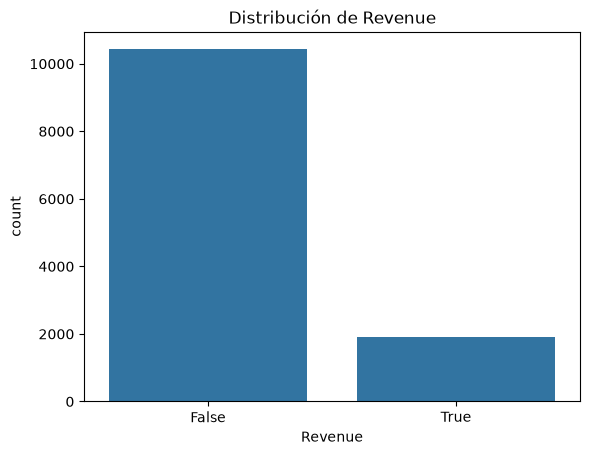

In [15]:
sns.countplot(data=df_clasificacion, x="Revenue")
plt.title("Distribución de Revenue")

Text(0.5, 1.0, 'Distribución de Revenue según VisitorType')

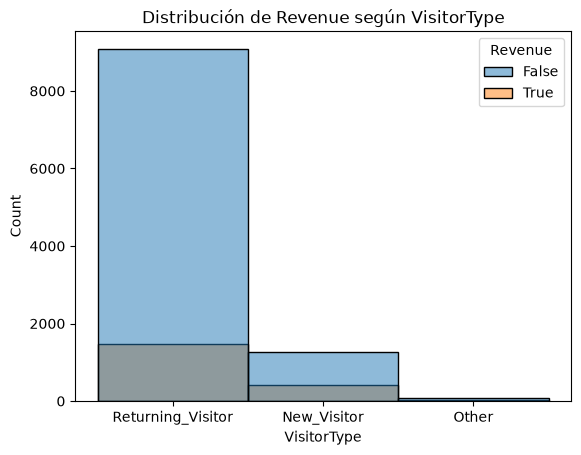

In [16]:
sns.histplot(data=df_clasificacion,x="VisitorType",hue="Revenue",bins=15).set_title("Distribución de Revenue según VisitorType")

Text(0.5, 1.0, 'Distribución de Revenue según Month')

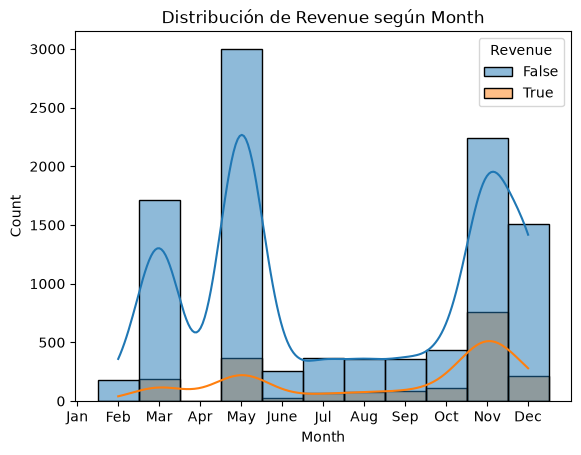

In [17]:
sns.histplot(data=df_clasificacion,x="Month",hue="Revenue",bins=15,kde=True).set_title("Distribución de Revenue según Month")

Text(0.5, 1.0, 'Duración en Páginas de Producto vs Tasa de Salida')

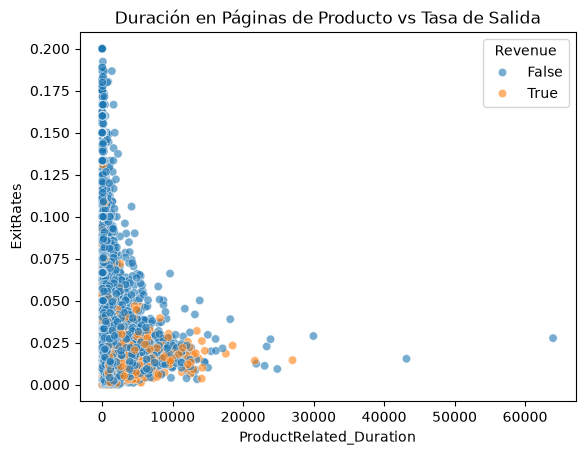

In [18]:
(sns.scatterplot(data=df_clasificacion, x='ProductRelated_Duration', y='ExitRates', hue='Revenue', alpha=0.6)
 .set_title("Duración en Páginas de Producto vs Tasa de Salida"))

Text(0.5, 1.0, 'Correlación entre métricas web')

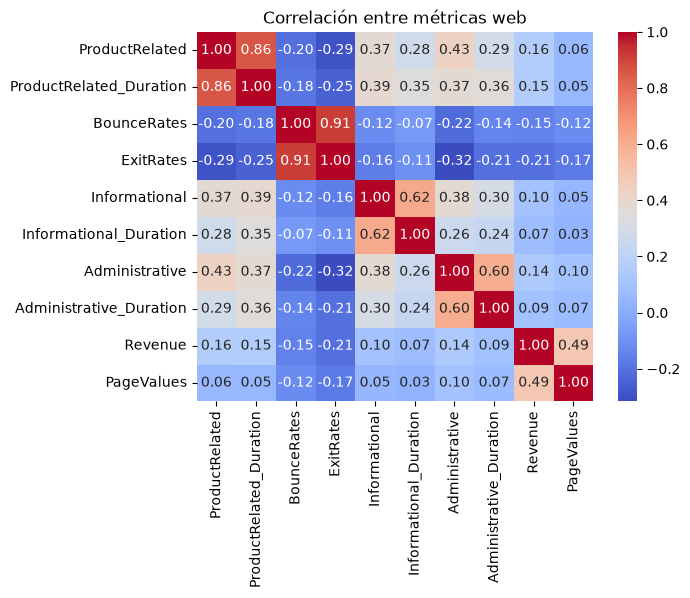

In [19]:
cols_num = ["ProductRelated", "ProductRelated_Duration","BounceRates","ExitRates","Informational",
            "Informational_Duration","Administrative","Administrative_Duration","Revenue","PageValues"]
sns.heatmap(df_clasificacion[cols_num].corr(), annot=True, cmap="coolwarm", fmt=".2f").set_title("Correlación entre métricas web")

<b>Conclusiones de la Exploración de la Fuente de Datos</b>

La fuente de datos contiene 12330 sesiones de navegación descritas por 18 columnas. La calidad general es buena: no hay valores nulos en ninguna columna, los tipos de datos son coherentes con la información que almacenan (conteos como enteros, duraciones y tasas como flotantes) y las variables categóricas no presentan errores tipográficos ni valores inconsistentes. VisitorType solo toma los valores New_Visitor, Returning_Visitor y Other, y Month registra únicamente 10 de los 12 meses del año, ya que no existen sesiones en enero ni en abril. Esto limita la capacidad del modelo para generalizar a esos periodos y debe tenerse presente al interpretar el efecto estacional.

El único problema de calidad detectado son 125 registros duplicados, que equivalen a cerca del 1% de la muestra. Se decidió eliminarlos antes de dividir los datos, porque una misma sesión repetida podría quedar en entrenamiento y en prueba a la vez, inflando artificialmente las métricas. Dado su bajo porcentaje, su eliminación no compromete la información disponible para el modelo.

La variable Revenue está fuertemente desbalanceada: 10422 sesiones (84.5%) no terminaron en compra y solo 1908 (15.5%) sí lo hicieron. Esto puede tener dos consecuencias posteriores. Primero, un modelo que prediga siempre <code>No compra</code> alcanzaría una exactitud cercana al 85% sin aprender nada, por lo que la exactitud no sirve como criterio principal y se debe evaluar con precisión, recall y F1-score. Segundo, la división de los datos debe ser estratificada para que entrenamiento y prueba conserven la misma proporción de compradores.

Las variables numéricas de navegación presentan una distribución muy asimétrica, con la mayoría de las sesiones concentradas en valores bajos y unas pocas con valores extremos. En ProductRelated_Duration la media es de 1194.7 con una desviación estándar de 1913.7, mientras que el máximo llega a 63973.5, unas 53 veces el promedio. Un patrón similar aparece en ProductRelated (media de 31.7 y máximo de 705), en Informational (media de 0.50 y máximo de 24) y en Administrative (media de 2.3 y máximo de 27). Además, las escalas son muy distintas entre variables, lo que justifica el escalado estándar para los modelos sensibles a la magnitud y sugiere que las transformaciones logarítmicas podrían ayudar a los modelos que asumen normalidad, como Naive Bayes.

La matriz de correlación revela dos pares de variables fuertemente relacionadas: BounceRates con ExitRates (0.91) y ProductRelated con ProductRelated_Duration (0.86). Por otro lado, PageValues es la variable más asociada con la compra, con una correlación de 0.49 con Revenue, por lo que se debe preservar íntegra durante todo el preprocesamiento.

Finalmente, la preparación de los datos debe considerar tres aspectos. Las variables Month y VisitorType son categóricas de texto y requieren dummificación. Weekend y Revenue son booleanas y deben convertirse a valores binarios. Las variables técnicas OperatingSystems, Browser, Region y TrafficType están codificadas como números, pero representan categorías sin un orden real, por lo que también deben tratarse como categóricas. Esto puede generar un número elevado de columnas, sobre todo en Browser y TrafficType por la naturaleza de ambas columnas, un aspecto que conviene vigilar por su posible efecto negativo sobre los modelos.

<h3>1.2 Identificación de las Variables</h3>
<p>
El conjunto de datos para este modelo de clasificación está compuesto por 10 atributos numéricos y 8 categóricos, destacando por no presentar ningún valor faltante en sus registros según lo obtenido en el análisis exploratorio. El objetivo principal del modelo es predecir la variable "Revenue", la cual es de tipo binario y actúa como la etiqueta de clase, indicando si una sesión finalizó o no en una transacción comercial.
    
Un grupo fundamental de características se basa en el comportamiento de navegación del usuario, cuyos valores se derivan de la información de la URL de las páginas y se actualizan en tiempo real a medida que el visitante interactúa con el sitio. Entre estas características se encuentran las variables de tipo entero "Administrative", "Informational" y "ProductRelated", que representan el número exacto de páginas administrativas, informativas y relacionadas con productos que fueron visitadas en una sesión. Asociadas a estas métricas de cantidad, las variables continuas "Administrative_Duration", "Informational_Duration" y "ProductRelated_Duration" (todas de tipo flotante) cuantifican el tiempo total que el usuario invirtió navegando dentro de cada una de esas categorías específicas.

El conjunto también incorpora métricas para evaluar el rendimiento de cada página del sitio de comercio electrónico. La variable continua "BounceRates" hace referencia al porcentaje de visitantes que entran al sitio web desde una página determinada y luego se van sin generar ninguna otra solicitud al servidor de análisis durante esa misma sesión. Por su parte, la característica continua "ExitRates" se calcula analizando todas las visualizaciones de una página para determinar el porcentaje de veces que dicha página fue la última de la sesión. Adicionalmente, se incluye la variable continua de tipo flotante "PageValues", la cual representa el valor promedio de una página web que un usuario visitó justo antes de completar con éxito una transacción comercial.

El aspecto temporal y la influencia de las fechas festivas también están capturados en la fuente de datos. La característica de tipo decimal "SpecialDay" indica qué tan cerca está la fecha de visita a un día especial (como el Día de San Valentín o el Día de las Madres) mediante los valores 0, 0.2, 0.4, 0.6, 0.8 y 1, considerando que en estas fechas las sesiones tienen una mayor probabilidad de culminar en una venta según las dinámicas de entrega y pedidos. Complementando este contexto temporal, se registran el mes del año a través de la variable categórica "Month" y un indicador binario llamado "Weekend", que especifica si la visita del usuario se llevó a cabo durante el fin de semana.

Finalmente, el dataset también contempla información técnica y demográfica sobre el perfil del usuario. Esto se logra mediante el uso de variables de tipo entero como "OperatingSystems", "Browser", "Region" y "TrafficType", que identifican el sistema operativo utilizado, el navegador web, la región geográfica de origen y la fuente o tipo de tráfico que dirigió al visitante al sitio web. A esto se suma la variable categórica "VisitorType", la cual clasifica al usuario para diferenciar si se trata de un visitante nuevo o de alguien recurrente en la plataforma.
</p>

<table style="border-collapse: collapse; width: 100%;">
  <caption style="text-align: left; font-weight: bold; padding: 6px 0;">Tabla de Variables</caption>
  <thead>
    <tr>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Nombre</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Rol</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Tipo</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Valores Faltantes</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="border: 1px solid gray; padding: 6px;">Administrative</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Administrative_Duration</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Informational</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Informational_Duration</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">ProductRelated</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">ProductRelated_Duration</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">BounceRates</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">ExitRates</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">PageValues</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">SpecialDay</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Month</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Texto</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">OperatingSystems</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Browser</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Region</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">TrafficType</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">VisitorType</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Texto</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Weekend</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Booleano</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Revenue</td><td style="border: 1px solid gray; padding: 6px;">Objetivo</td><td style="border: 1px solid gray; padding: 6px;">Booleano</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
  </tbody>
</table>
<i>Tabla de variables identificadas en Online Shoppers Purchasing Intention (UCI).</i>

<h3>1.3 Variable Objetivo del Problema</h3>
<p>
El objetivo principal de la creación del modelo de clasificación es predecir de manera precisa si la sesión de un usuario en el sitio de comercio electrónico finalizará en una transacción, utilizando la variable binaria "Revenue" como etiqueta de clase a predecir. Al evaluar el comportamiento de navegación en tiempo real, el perfil del visitante y las métricas de interacción recopiladas, el algoritmo debe aprender los patrones y comportamientos específicos que diferencian a un comprador de un visitante que abandona la página sin comprar.
    
Desde un punto de vista analítico y comercial, el propósito de clasificar de forma predictiva estas interacciones puede ofrecer una gran variedad de beneficios, con esto se busca transformar los datos crudos de tráfico web y características de sesión en información estratégica y accionable. Al identificar qué características o combinaciones de variables son más determinantes para concretar una venta, el modelo puede proporcionar información valiosa para que el negocio pueda optimizar la experiencia del usuario, retener clientes potenciales y diseñar estrategias orientadas a maximizar la tasa de conversión general del sitio.

</p>

<h3>1.4 Preparación y Preprocesamiento de los Modelos</h3>
<p>Para preparar y preprocesar los datos antes de entrenar los modelos, inicialmente se eliminan los registros duplicados presentes en la fuente de datos y se reinicia el índice del DataFrame para asegurar su consistencia estructural. A continuación, se aísla la variable objetivo Revenue, transformándola a un formato numérico entero (astype(int)), y se separan las características restantes como variables predictoras independientes.
</p>

In [20]:
df_clasificacion = df_clasificacion.drop_duplicates().reset_index(drop=True)
y_clasificacion = df_clasificacion["Revenue"].astype(int)

<b>Aplicación de Ingeniería de Carácteristicas</b>

Antes de dividir los datos y entrenar los modelos, se aplica un proceso de ingeniería de características con el objetivo de reducir la redundancia entre variables y de resumir el comportamiento de navegación en un conjunto más compacto de atributos. Esta decisión responde a los hallazgos del análisis exploratorio, donde se identificó que variables como ProductRelated y ProductRelated_Duration presentan una correlación de 0.86, y que BounceRates y ExitRates alcanzan una correlación de 0.91. Mantener todas estas variables aportaría información repetida y afectaría sobre todo a los modelos sensibles a la dependencia entre predictores, como Naive Bayes.

Primero se crean dos nuevas variables a partir de los conteos de páginas visitadas. La variable TotalPages se obtiene sumando las páginas administrativas, informativas y relacionadas con productos, de modo que representa el volumen total de navegación de la sesión. Por su parte, ProductShare se calcula dividiendo ProductRelated entre TotalPages, lo que indica qué proporción de la sesión se dedicó a páginas de productos y permite distinguir entre usuarios que exploran el catálogo y usuarios que visitan principalmente otras secciones. Para evitar divisiones entre cero en las sesiones sin páginas registradas, los ceros de TotalPages se reemplazan temporalmente por valores nulos y el resultado de esas sesiones se completa con 0 mediante <code>fillna(0)</code>.

Posteriormente se eliminan las columnas que quedan cubiertas por las nuevas variables o que no se consideran convenientes para el modelo. Se descartan ProductRelated, Administrative e Informational, porque su información está resumida en TotalPages y ProductShare (sus duraciones se conservan como variables independientes). También se elimina BounceRates, ya que está fuertemente relacionada con ExitRates, que sí se mantiene. Finalmente, se excluyen Browser y OperatingSystems, que son códigos numéricos de categorías sin un orden real y que, al dummificarse, aumentarían considerablemente el número de columnas del conjunto sin aportar una relación clara con la intención de compra y no guardan una relación tan significativa con Revenue.

Estas transformaciones se realizan fila por fila y no aprenden ningún parámetro de los datos, por lo que aplicarlas antes de la división entre entrenamiento y prueba no genera fuga de información. Una vez creadas las variables y eliminadas las columnas, se separa la variable objetivo Revenue del resto de las características, que quedan almacenadas en X_clasificacion como los predictores del modelo.

In [21]:
df_clasificacion["TotalPages"] = (df_clasificacion["Administrative"]
                                  + df_clasificacion["Informational"]
                                  + df_clasificacion["ProductRelated"])

df_clasificacion["ProductShare"] = (df_clasificacion["ProductRelated"]
                                    / df_clasificacion["TotalPages"].replace(0, np.nan)).fillna(0)

In [22]:
df_clasificacion = df_clasificacion.drop(columns=["ProductRelated","BounceRates", "Administrative","Informational","Browser","OperatingSystems"])
X_clasificacion = df_clasificacion.drop(columns="Revenue")

<b>Información del Nuevo Conjunto de Datos</b>

<table style="border-collapse: collapse; width: 100%;">
  <caption style="text-align: left; font-weight: bold; padding: 6px 0;">Tabla de Variables de Entrenamiento</caption>
  <thead>
    <tr>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Nombre</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Tipo</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Categoría de Información</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Descripción</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="border: 1px solid gray; padding: 6px;">Administrative_Duration</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">Comportamiento de navegación</td><td style="border: 1px solid gray; padding: 6px;">Tiempo total que el usuario pasó en páginas administrativas durante la sesión.</td></tr>
    <tr style="background-color: #f5f5f5;"><td style="border: 1px solid gray; padding: 6px;">Informational_Duration</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">Comportamiento de navegación</td><td style="border: 1px solid gray; padding: 6px;">Tiempo total que el usuario pasó en páginas informativas durante la sesión.</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">ProductRelated_Duration</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">Comportamiento de navegación</td><td style="border: 1px solid gray; padding: 6px;">Tiempo total que el usuario pasó en páginas relacionadas con productos.</td></tr>
    <tr style="background-color: #f5f5f5;"><td style="border: 1px solid gray; padding: 6px;">TotalPages</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">Comportamiento de navegación</td><td style="border: 1px solid gray; padding: 6px;">Suma de páginas administrativas, informativas y de productos visitadas en la sesión (variable creada).</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">ProductShare</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">Comportamiento de navegación</td><td style="border: 1px solid gray; padding: 6px;">Proporción de las páginas visitadas que corresponden a productos, entre 0 y 1 (variable creada).</td></tr>
    <tr style="background-color: #f5f5f5;"><td style="border: 1px solid gray; padding: 6px;">ExitRates</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">Rendimiento de las páginas</td><td style="border: 1px solid gray; padding: 6px;">Porcentaje promedio de visualizaciones de las páginas visitadas que fueron la última de la sesión.</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">PageValues</td><td style="border: 1px solid gray; padding: 6px;">Flotante</td><td style="border: 1px solid gray; padding: 6px;">Rendimiento de las páginas</td><td style="border: 1px solid gray; padding: 6px;">Valor promedio de las páginas visitadas antes de completar una transacción.</td></tr>
    <tr style="background-color: #f5f5f5;"><td style="border: 1px solid gray; padding: 6px;">SpecialDay</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">Contexto temporal</td><td style="border: 1px solid gray; padding: 6px;">Cercanía de la visita a una fecha especial (0, 0.2, 0.4, 0.6, 0.8 o 1).</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Month</td><td style="border: 1px solid gray; padding: 6px;">Texto</td><td style="border: 1px solid gray; padding: 6px;">Contexto temporal</td><td style="border: 1px solid gray; padding: 6px;">Mes del año en que se realizó la sesión.</td></tr>
    <tr style="background-color: #f5f5f5;"><td style="border: 1px solid gray; padding: 6px;">Weekend</td><td style="border: 1px solid gray; padding: 6px;">Booleano</td><td style="border: 1px solid gray; padding: 6px;">Contexto temporal</td><td style="border: 1px solid gray; padding: 6px;">Indica si la visita ocurrió en fin de semana.</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Region</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">Perfil del usuario</td><td style="border: 1px solid gray; padding: 6px;">Código de la región geográfica de origen del visitante (categoría sin orden).</td></tr>
    <tr style="background-color: #f5f5f5;"><td style="border: 1px solid gray; padding: 6px;">TrafficType</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">Perfil del usuario</td><td style="border: 1px solid gray; padding: 6px;">Código de la fuente de tráfico que llevó al visitante al sitio (categoría sin orden).</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">VisitorType</td><td style="border: 1px solid gray; padding: 6px;">Texto</td><td style="border: 1px solid gray; padding: 6px;">Perfil del usuario</td><td style="border: 1px solid gray; padding: 6px;">Clasifica al visitante como nuevo, recurrente u otro.</td></tr>
  </tbody>
</table>
<i>Variables utilizadas como predictores en el entrenamiento. La variable objetivo es Revenue (booleana), que indica si la sesión terminó en compra.</i>

Text(0.5, 1.0, 'Correlación entre métricas web')

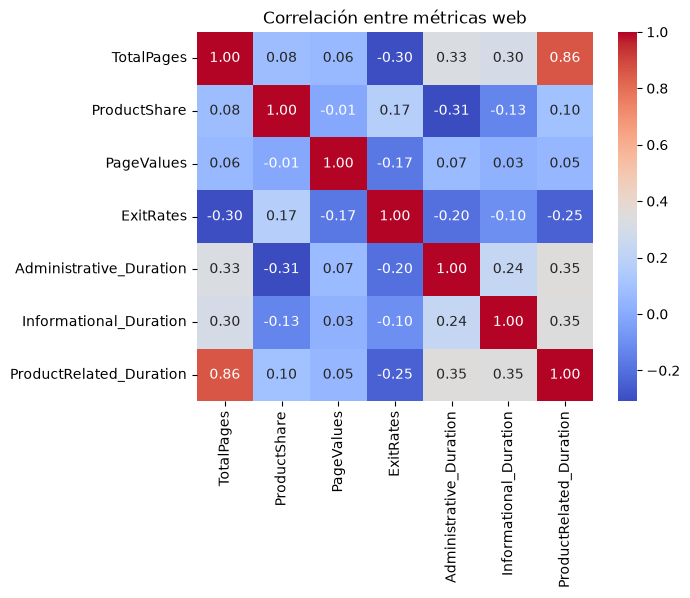

In [24]:
cols = ["TotalPages", "ProductShare", "PageValues", "ExitRates","Administrative_Duration","Informational_Duration","ProductRelated_Duration"]
sns.heatmap(df_clasificacion[cols].corr(), annot=True, cmap="coolwarm", fmt=".2f").set_title("Correlación entre métricas web")

In [23]:
df_clasificacion.info()

<class 'pandas.DataFrame'>
RangeIndex: 12205 entries, 0 to 12204
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype   
---  ------                   --------------  -----   
 0   Administrative_Duration  12205 non-null  float64 
 1   Informational_Duration   12205 non-null  float64 
 2   ProductRelated_Duration  12205 non-null  float64 
 3   ExitRates                12205 non-null  float64 
 4   PageValues               12205 non-null  float64 
 5   SpecialDay               12205 non-null  float64 
 6   Month                    12205 non-null  category
 7   Region                   12205 non-null  int64   
 8   TrafficType              12205 non-null  int64   
 9   VisitorType              12205 non-null  str     
 10  Weekend                  12205 non-null  bool    
 11  Revenue                  12205 non-null  bool    
 12  TotalPages               12205 non-null  int64   
 13  ProductShare             12205 non-null  float64 
dtypes: bool(2), categ

<b>Aplicación de Transformaciones al Conjunto de Datos</b>

Dado que el análisis exploratorio demostró que los valores de la variable a predecir (Revenue) están distribuidos de forma marcadamente desigual, es imperativo mantener su proporción exacta al dividir la muestra. Por ello, se utiliza la función <code>train_test_split</code> configurada para destinar un 80% de los datos a la fase de entrenamiento y el 20% restante a la de pruebas, aplicando el parámetro de estratificación sobre la variable objetivo para garantizar que ambos subconjuntos conserven la distribución representativa de la fuente de datos original.

In [25]:
X_trainclass, X_testclass, y_trainclass, y_testclass = train_test_split(X_clasificacion, y_clasificacion, test_size=0.2
                                                                        , random_state=42, stratify=y_clasificacion)

<p>Para que los modelos de clasificación utilicen correctamente las variables categóricas, se debe considerar que, por su naturaleza, estos algoritmos solo pueden procesar valores numéricos. Por ello, es necesario aplicar técnicas de codificación que conviertan las categorías en una representación numérica sin introducir órdenes o jerarquías que no existen entre ellas. Para esto, primero se deben identificar cuáles variables son categóricas y cuáles son numéricas, de manera que a cada grupo se le aplique la transformación que le corresponde.</p>

In [26]:
columnas_categoricas = ["Month", "VisitorType", "Weekend", "TrafficType","Region"]
columnas_numericas = [c for c in X_clasificacion.columns if c not in columnas_categoricas]
print("Columnas Numéricas:", columnas_numericas)
print("Columnas Categóricas:", columnas_categoricas)

Columnas Numéricas: ['Administrative_Duration', 'Informational_Duration', 'ProductRelated_Duration', 'ExitRates', 'PageValues', 'SpecialDay', 'TotalPages', 'ProductShare']
Columnas Categóricas: ['Month', 'VisitorType', 'Weekend', 'TrafficType', 'Region']


Las variables numéricas se escalan con <b>StandardScaler</b>, una técnica que transforma cada característica para que tenga media 0 y desviación estándar 1. Esto evita que las variables con rangos amplios, como ProductRelated_Duration, dominen sobre las de rangos pequeños. Este escalado se aplicó a todas las columnas numéricas de tipo entero y flotante.

Las variables categóricas, como Month y VisitorType, toman valores en forma de texto que los modelos no pueden procesar directamente. Para resolverlo se aplica una dummificación con <b>OneHotEncoder</b>, que reemplaza cada variable categórica por varias columnas binarias, una por categoría. En cada fila, la columna correspondiente a la categoría observada toma el valor 1 y las demás toman el valor 0. Así, la información categórica queda en formato numérico sin asignar un orden artificial entre las categorías.

Una vez definidas las variables numéricas y las categóricas, se utiliza el objeto <b>ColumnTransformer</b>, que permite aplicar cada transformación solo a su grupo de columnas: el escalado estándar a las numéricas y la dummificación a las categóricas. De esta forma, ambos procesos se ejecutan de manera conjunta y ordenada sobre el conjunto de datos.


<b>Nombre:</b> crear_preprocesador <br>
<b>Argumentos:</b> <br>
    <b>(boolean) escalar:</b> Representa si los datos requieren escalado estándar o no. <br>
<b>Objetivo: </b> Crear un preprocesador que realice la dummificación y escalado estándar de las columnas. <br>
<b>Retorno:</b> (ColumTransformer) Retorna un ColumnTransformer que contiene los procesos de prepración.

In [27]:
def crear_preprocesador(escalar=True):
    prep = ColumnTransformer(transformers=[
        ("num", StandardScaler() if escalar else "passthrough", columnas_numericas),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), columnas_categoricas)
    ], verbose_feature_names_out=False)
    prep.set_output(transform="pandas")
    return prep

<b>Vista Previa del Conjunto de Entrenamiento</b>

Para conocer mejor el conjunto de entrenamiento se debe crear una versión de prueba utilizando el método fit_transform. El objetivo principal de este paso es transformar y estandarizar automáticamente la información original para que tenga el formato numérico y la escala adecuada que exige un modelo predictivo. Esta fase de preparación es fundamental porque la mayoría de los algoritmos de clasificación no pueden interpretar variables de texto de forma nativa y resultan altamente sensibles a las diferencias de magnitud entre las variables numéricas. Por lo tanto, adecuar los datos antes del entrenamiento garantiza que el modelo procese la información correctamente y no desarrolle sesgos perjudiciales.

In [28]:
prep_vis = crear_preprocesador()
X_train_transf = prep_vis.fit_transform(X_trainclass)

print("Antes: ", X_trainclass.shape)
print("Después:", X_train_transf.shape)

Antes:  (9764, 13)
Después: (9764, 51)


In [29]:
display(X_train_transf.head())

,Administrative_Duration,Informational_Duration,ProductRelated_Duration,ExitRates,PageValues,SpecialDay,TotalPages,ProductShare,Month_Aug,Month_Dec,...,TrafficType_20,Region_1,Region_2,Region_3,Region_4,Region_5,Region_6,Region_7,Region_8,Region_9
7469,0.676238,-0.243015,-0.080395,-0.800192,1.665596,-0.311837,0.342413,-0.564653,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0
11804,-0.458067,-0.243015,-0.158842,-0.739774,1.495448,-0.311837,-0.105739,0.672764,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
3250,-0.458067,-0.243015,-0.408089,-0.287446,-0.315264,3.689185,-0.468529,0.672764,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
204,-0.235218,-0.243015,-0.336795,-0.279507,-0.315264,-0.311837,-0.596572,-1.330672,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
4392,-0.458067,-0.243015,0.203501,-0.609743,-0.315264,-0.311837,-0.404507,0.672764,0.0,0.0,...,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [30]:
display(X_train_transf[columnas_numericas].describe().loc[["mean","std"]].round(3))

,Administrative_Duration,Informational_Duration,ProductRelated_Duration,ExitRates,PageValues,SpecialDay,TotalPages,ProductShare
mean,-0.0,-0.0,-0.0,0.0,0.0,0.0,0.0,-0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


In [31]:
ohe = prep_vis.named_transformers_["cat"]
resumen = pd.DataFrame({
    "Variable": columnas_categoricas,
    "Columnas generadas": [len(c) for c in ohe.categories_],
    "Categorías": [list(c) for c in ohe.categories_]
})
display(resumen)

,Variable,Columnas generadas,Categorías
0,Month,10,"[Aug, Dec, Feb, Jul, June, Mar, May, Nov, Oct,..."
1,VisitorType,3,"[New_Visitor, Other, Returning_Visitor]"
2,Weekend,2,"[False, True]"
3,TrafficType,19,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15..."
4,Region,9,"[1, 2, 3, 4, 5, 6, 7, 8, 9]"


Al analizar los resultados generados por el preprocesador, se evidencian cambios estructurales y de valor significativos en el conjunto de datos que responden a dos procesos de transformación específicos. En primer lugar, se observa un aumento drástico en la dimensionalidad, pasando de las 13 columnas originales del conjunto de entrenamiento a un total de 51. Esto sucede por la aplicación de la codificación One-Hot Encoding sobre las variables categóricas, un método que crea una nueva columna binaria por cada categoría única existente; como lo demuestra la tabla de resumen, la variable Month generó 10 columnas, VisitorType 3, Weekend 2, TrafficType 19 y Region 9, lo que explica la expansión horizontal del DataFrame.

En segundo lugar, se alteraron los valores de las columnas numéricas mediante un proceso de escalado estándar. La descripción estadística de los datos transformados confirma que todas las variables numéricas (como Administrative_Duration o ProductRelated_Duration) fueron ajustadas para presentar una media de 0.0 y una desviación estándar de 1.0. Este cambio ocurre para convertir las métricas originales en puntuaciones Z, unificando sus escalas para asegurar que todas las variables tengan el mismo peso matemático durante el entrenamiento y ninguna domine las predicciones simplemente por poseer una magnitud inherentemente mayor.

<h3>1.5 Construcción de los Modelos</h3>
<p>Luego de que se realizó el preprocesamiento, se construyen dos modelos con <b>scikit-learn</b> sobre la partición 80 % / 20 % estratificada que se definió anteriormente. En este apartado se realizará simplemente la operación de entrenamiento con Naive Bayes y con Árboles Decisorios. Para el proceso de entrenamiento se incluyó en un Pipeline la secuencia de pasos que debe implementar cada modelo, para así asegurar que la etapa de preprocesamiento se realice antes que el proceso de entrenamiento.</p>


<b>Entrenamiento del Modelo de Clasificación por Naive Bayes</b>

Para garantizar que los datos ingresen al modelo en un formato óptimo, se definió previamente una función encargada de estructurar las reglas de preprocesamiento. Esta configuración establece una secuencia lógica donde las variables numéricas son estandarizadas para unificar sus escalas, mientras que las variables categóricas son codificadas a un formato binario. El objetivo de centralizar estos pasos es automatizar la adecuación matemática de los datos antes de introducirlos a cualquier algoritmo.

Posteriormente, para la construcción del modelo predictivo, se implementó una estructura secuencial mediante un Pipeline de scikit-learn. En este flujo de trabajo se acopló la etapa de preprocesamiento definida anteriormente con el algoritmo de clasificación seleccionado, en este caso, un modelo Naive Bayes. Al igual que en el ejemplo provisto, la consideración principal para utilizar este Pipeline fue asegurar estrictamente que las transformaciones de los datos se realicen antes que el proceso de entrenamiento, evitando fugas de información y garantizando que el modelo aprenda sobre una base estandarizada.

Finalmente, con la secuencia del Pipeline consolidada, se llevó a cabo la operación de entrenamiento alimentando el sistema con la partición de datos correspondiente al aprendizaje. Una vez que el modelo ajustó sus parámetros y reconoció los patrones, se procedió a generar las predicciones sobre el conjunto de pruebas restante. Gracias a la estructura definida, estas nuevas observaciones pasaron automáticamente por las mismas reglas de preprocesamiento memorizadas durante el entrenamiento antes de ser clasificadas, asegurando una evaluación íntegra y consistente. 

In [32]:
modelo_nb = Pipeline([("prep", crear_preprocesador()), ("clf", GaussianNB())])
modelo_nb.fit(X_trainclass, y_trainclass)
pred_nb = modelo_nb.predict(X_testclass)

<b>Funciones Auxiliares para Entrenamiento</b>

<b>Nombre:</b> calcular_min_samples_leaf <br>
<b>Argumentos:</b> <br>
    <b>(int) n_muestras:</b> Representa la cantidad total de muestras que se tomaran de referencia. <br>
    <b>(float) proporcion:</b> Representa la cantidad de elementos que se tomaran como referencia en base al total. (0.5% base) <br>
    <b>(int) minimo:</b> Representa la cantidad mínimo de casos que debería tomar una hoja. (5 base) <br>
<b>Objetivo: </b> Obtener la cantidad de mínima de ejemplares necesarios que debería tener una hoja. <br>
<b>Retorno:</b> (int) Retorna la cantidad mínima de ejemplares necesarios en una hoja que se necesitan para que representen un porcentaje proporcional.

In [33]:
def calcular_min_samples_leaf(n_muestras, proporcion=0.005, minimo=5):
    return max(minimo, int(np.ceil(n_muestras * proporcion)))

<b>Entrenamiento del Modelo de Clasificación por Árboles Decisorios</b>

Para iniciar la configuración del modelo de Árboles de Decisión, la secuencia lógica comienza calculando dinámicamente el número mínimo de muestras requeridas para formar un nodo hoja en función del volumen total del conjunto de entrenamiento. Esta consideración actúa como un mecanismo preventivo para controlar el crecimiento del árbol y evitar el sobreajuste. A continuación, se construye un Pipeline para acoplar la fase de preprocesamiento con el algoritmo predictivo, tomando la decisión técnica de desactivar explícitamente el escalado de variables (escalar=False). Esta omisión es intencional y se justifica matemáticamente porque los modelos basados en árboles realizan divisiones evaluando si un valor es mayor o menor que un umbral, ignorando las distancias espaciales entre los puntos, lo que vuelve innecesaria la estandarización de las escalas numéricas. 

En la etapa de modelado, el clasificador de Árboles de Decisión se integra al flujo con restricciones estructurales rígidas: una profundidad máxima de 5 niveles, el tamaño mínimo de hoja previamente calculado siendo igual a un 0.5% de los datos y una semilla de aleatoriedad fija (random_state=42) para garantizar que los resultados sean siempre reproducibles. Con esta definición completamente consolidada, el sistema ejecuta la operación de entrenamiento para deducir las reglas de clasificación y, de forma secuencial, genera las predicciones sobre el conjunto de pruebas. Gracias al Pipeline, las observaciones nuevas son procesadas automáticamente bajo las mismas directrices antes de ser clasificadas, garantizando la integridad de los resultados obtenidos. 

In [34]:
min_leaf = calcular_min_samples_leaf(len(X_trainclass))

modelo_dt = Pipeline([("prep", crear_preprocesador(escalar=False)),
                      ("clf", DecisionTreeClassifier(max_depth=5, min_samples_leaf=min_leaf, random_state=42))])
modelo_dt.fit(X_trainclass, y_trainclass)
pred_dt = modelo_dt.predict(X_testclass)

<h3>Funciones para Evaluación de los Modelos</h3>

<b>Nombre:</b> metricas_manuales <br>
<b>Argumentos:</b> <br>
    <b>(Series) y_real:</b> Representa el valor real que tiene la variable y en el dataframe. <br>
    <b>(Series) y_pred:</b> Representa los valores obtenidos mediante las predicciones del modelo. <br>
<b>Objetivo: </b> Obtener las métricas manuales que corresponden a métodos de evaluación del modelo y la matriz de confusión. <br>
<b>Retorno:</b> (Dictionary) Retorna un conjunto de valores ordenados de forman clave-valor que representan los resultados obtenidos de cada una de las métricas.

In [35]:
def metricas_manuales(y_real, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_real, y_pred).ravel()
    accuracy = (tp + tn) / (tp + tn + fp + fn)
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0.0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0.0
    return {"TN": tn, "FP": fp, "FN": fn, "TP": tp,
            "Accuracy": accuracy, "Precision": precision, "Recall": recall, "F1": f1}


<b>Nombre:</b> comparar_manual_vs_sklearn <br>
<b>Argumentos:</b> <br>
    <b>(String) nombre:</b> Representa el nombre del modelo que se va a utilizar en la comparación. <br>
    <b>(Series) y_real:</b> Representa el valor real que tiene la variable y en el dataframe. <br>
    <b>(Series) y_pred:</b> Representa los valores obtenidos mediante las predicciones del modelo. <br>
<b>Objetivo: </b> Comparar los resultados de las métricas manuales y las métricas de sklearn e imprimir el resultado <br>
<b>Retorno:</b> (Dictionary) Retorna un conjunto de valores ordenados de forman clave-valor que representan los resultados obtenidos de cada una de las métricas.

In [36]:
def comparar_manual_vs_sklearn(nombre, y_real, y_pred):
    m = metricas_manuales(y_real, y_pred)
    sk = {"Accuracy": accuracy_score(y_real, y_pred), "Precision": precision_score(y_real, y_pred),
          "Recall": recall_score(y_real, y_pred), "F1": f1_score(y_real, y_pred)}
    tabla = pd.DataFrame({"Manual": {k: m[k] for k in sk}, "scikit-learn": sk})
    tabla["Diferencia"] = (tabla["Manual"] - tabla["scikit-learn"]).abs()
    print(f"=== {nombre} ===")
    print(f"TN={m["TN"]}  FP={m["FP"]}  FN={m["FN"]}  TP={m["TP"]}")
    display(tabla.round(4))
    return m

<b>Nombre:</b> graficar_matriz_confusion <br>
<b>Argumentos:</b> <br>
    <b>(String) nombre:</b> Representa el nombre del modelo que se va a utilizar en la comparación. <br>
    <b>(Series) y_real:</b> Representa el valor real que tiene la variable y en el dataframe. <br>
    <b>(Series) y_pred:</b> Representa los valores obtenidos mediante las predicciones del modelo. <br>
<b>Objetivo: </b> Graficar la matriz de confusión de un modelo. <br>
<b>Retorno:</b> -

In [37]:
def graficar_matriz_confusion(nombre, y_real, y_pred):
    fig, ax = plt.subplots(figsize=(6, 5))
    ConfusionMatrixDisplay.from_predictions(
        y_real, y_pred,
        display_labels=["No compra", "Compra"],
        cmap="Blues", ax=ax, colorbar=True,
        normalize=None,
        values_format="d"
    )
    ax.set_title(f"Matriz de confusión - {nombre}")
    plt.tight_layout()
    plt.show()


<h3>1.6 Evaluación de los Modelos de Clasificación</h3>

<i>Observaciones</i>

Para estos escenarios se tomo como positivo el caso donde sucede una compra y como negativo aquellos casos donde una sesión no concluye en compra, por lo tanto, la asociación de TP, FP, TN, FN corresponde de la siguiente forma:

<b>TP</b> corresponde a esos casos donde el modelo definió que era una compra y efectivamente fue una.

<b>FP</b> corresponde a esos casos donde el modelo definió que era una compra y la sesión realmente no concluyó en una.

<b>TN</b> corresponde a esos casos donde el modelo definió que no era una compra y la sesión realmente no concluyó en una.

<b>FN</b> corresponde a esos casos donde el modelo definió que no era una compra y la sesión realmente si fue una compra.

<p>Para evaluar los resultados de los modelos, luego de que realicen las predicciones se tomaron en cuenta un conjunto de métricas que permiten conocer el comportamiento del modelo y así poder determinar si el resultado logrado es el apropiado, las métricas que se están considerando son las siguientes: </p>
<ul>
    <li><b>Exactitud</b> = (TP + TN) / (TP + TN + FP + FN)</li>
    <li><b>Precisión</b> = TP / (TP + FP)</li>
    <li><b>Recall</b> = TP / (TP + FN)</li>
    <li><b>F1</b> = 2 · Precisión · Recall / (Precisión + Recall)</li>
</ul>

Estas medidas se obtuvieron experimentalmente de dos fuentes diferentes, la primera calculando manualmente las métricas utilizando la función <code> metricas_manuales</code> que se encuentra en el apartado de Funciones Manuales para evaluación de los modelos y luego se obtuvieron utilizando las funciones predefinidas por sklearn que sirven para conocer el comportamiento del modelo.

<b>Resultados Evaluativos de Naive Bayes</b>

In [38]:
m_nb = comparar_manual_vs_sklearn("Naive Bayes", y_testclass, pred_nb)

=== Naive Bayes ===
TN=277  FP=1782  FN=2  TP=380


,Manual,scikit-learn,Diferencia
Accuracy,0.2692,0.2692,0.0
Precision,0.1758,0.1758,0.0
Recall,0.9948,0.9948,0.0
F1,0.2987,0.2987,0.0


In [39]:
print("Naive Bayes\n", classification_report(y_testclass, pred_nb, target_names=["No compra", "Compra"]))

Naive Bayes
               precision    recall  f1-score   support

   No compra       0.99      0.13      0.24      2059
      Compra       0.18      0.99      0.30       382

    accuracy                           0.27      2441
   macro avg       0.58      0.56      0.27      2441
weighted avg       0.86      0.27      0.25      2441



<b>Interpretación de las Métricas de Naive Bayes</b>

La evaluación de las métricas del modelo Naive Bayes revela un comportamiento predictivo altamente sesgado hacia la clase positiva (<code>Compra</code>), lo que resulta en un rendimiento global deficiente reflejado en una exactitud (Accuracy) de apenas el 26.92%. Esta configuración indica que el algoritmo está clasificando de manera general la gran mayoría de las sesiones de los usuarios como <code>Compra</code>, fracasando en la identificación de aquellos clientes que no tienen intención de adquirir nada, lo cual se confirma al observar el bajísimo recall de 0.13 (13%) para la clase <code>No compra</code> en el reporte de clasificación.

Esta tendencia a sobreestimar las conversiones genera un contraste extremo entre la sensibilidad y la precisión del modelo. Por un lado, el modelo logra un Recall del 99.48% para la clase <code>Compra</code>, habiendo dejado escapar únicamente 2 casos reales frente a 380 compras correctamente identificadas. Sin embargo, el costo analítico de forzar el modelo para capturar casi todas las compras reales es el desplome de su precisión (Precision) a un escaso 17.58%, lo que significa que más del 80% de las veces que el sistema predijo una conversión, se trató de una falsa alarma. En consecuencia, el F1-score se ubica en 0.30 para la clase positiva, demostrando que este modelo carece del equilibrio necesario para ser útil en un entorno real y sugiere que el algoritmo Bayesiano no logra interpretar correctamente las correlaciones de este conjunto de datos.

<b>Matriz de Confusión de Naive Bayes</b>

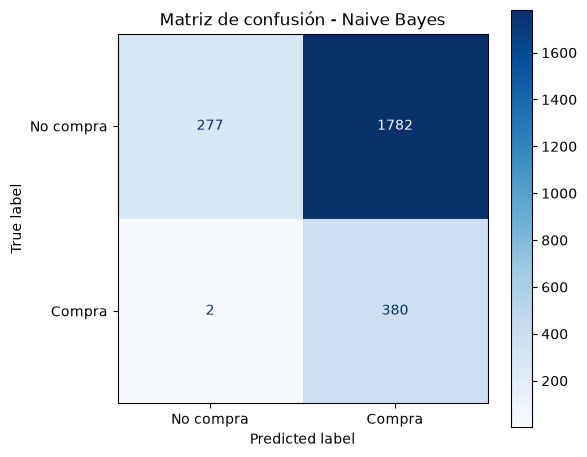

In [40]:
graficar_matriz_confusion("Naive Bayes", y_testclass, pred_nb)

<b>Interpretación de la Matriz de Confusión</b>

La matriz de confusión visualiza de forma detallada el desempeño del modelo Naive Bayes al contrastar las intenciones reales de los usuarios (True label) frente a las clasificaciones emitidas por el algoritmo (Predicted label). En el eje superior se evalúa el comportamiento ante los casos negativos: el cuadrante superior izquierdo muestra 277 verdaderos negativos (TN), representando las sesiones donde el modelo acertó al predecir que no habría compra. Sin embargo, el cuadrante superior derecho domina visualmente la gráfica con un tono azul oscuro, revelando 1782 falsos positivos (FP); es decir, el sistema se equivocó masivamente al etiquetar como <code>Compra</code> a clientes que en la realidad no adquirieron nada.

Por otro lado, la mitad inferior de la matriz refleja la respuesta del modelo ante las verdaderas conversiones. El cuadrante inferior izquierdo registra únicamente 2 falsos negativos (FN), indicando que el algoritmo casi nunca omitió a un comprador real clasificándolo erróneamente en la categoría de <code>No compra</code>. Consiguientemente, el cuadrante inferior derecho contabiliza 380 verdaderos positivos (TP), que corresponden a las transacciones exitosas que el modelo logró identificar de manera correcta.

Esta distribución de valores conduce a la conclusión analítica de que el algoritmo padece un sesgo predictivo severo. Lógicamente, el modelo adoptó un comportamiento de clasificación donde prioriza capturar absolutamente todas las ventas posibles (acertando 380 casos reales frente a solo 2 omisiones), pero asume el costo de generar 1782 falsas alarmas para lograrlo. Esta incapacidad para discriminar los verdaderos casos negativos demuestra que las reglas probabilísticas del enfoque Naive Bayes resultaron ineficaces para conducir a una decisión equilibrada en este conjunto de datos.

<b>Justificación de los Resultados de Naive Bayes</b>

El bajo rendimiento del modelo Naive Bayes se explica fundamentalmente por la violación de su premisa matemática central: la condición de independencia entre las variables predictoras. Como se evidenció en la matriz de correlación durante el análisis exploratorio inicial, existen características fuertemente ligadas linealmente en este conjunto de datos, tales como BounceRates y ExitRates (0.91), o ProductRelated y su respectiva duración (0.86). Aunque en la preparación se eliminaron BounceRates y ProductRelated y se conservó solo ExitRates, la redundancia persiste: la variable TotalPages incluye a ProductRelated y mantiene una correlación de 0.86 con ProductRelated_Duration. Al procesar variables altamente correlacionadas, el algoritmo Bayesiano es incapaz de reconocer la redundancia y trata a cada una como una evidencia independiente; como resultado, sobrepondera artificialmente el peso de estas métricas, empujando al modelo a tomar decisiones inexactas.

En segundo lugar, se utilizó la variante GaussianNB, que asume que cada variable numérica sigue una distribución normal dentro de cada clase. La exploración mostró que las métricas de duración y conteo de páginas tienen una asimetría severa, con colas largas y muchos ceros. El escalado estándar solo centra y reescala los valores, pero no corrige esa asimetría, por lo que la curva gaussiana ajustada representa mal los datos y las verosimilitudes resultantes son poco confiables.

Finalmente, el One-Hot Encoding expandió el conjunto a 51 columnas, de las cuales la gran mayoría son indicadores binarios (0/1). GaussianNB modela cada una como si fuera continua y normal; en una columna binaria donde casi todas las filas valen 0, la varianza estimada por clase es muy pequeña, y basta que una observación valga 1 para que su fiabilidad sea extrema. Como Naive Bayes multiplica las contribuciones de todas las columnas bajo el supuesto de independencia, decenas de columnas dummy aportan evidencia exagerada y correlacionada, y esto empuja la predicción hacia la clase <code>Compra</code> en la mayoría de las sesiones. Es decir, el problema no es solo el algoritmo, sino la combinación de GaussianNB con esta representación de los datos.

<b>Resultados Evaluativos de Arboles Decisorios</b>

In [41]:
m_dt = comparar_manual_vs_sklearn("Árbol de Decisión", y_testclass, pred_dt)

=== Árbol de Decisión ===
TN=1975  FP=84  FN=145  TP=237


,Manual,scikit-learn,Diferencia
Accuracy,0.9062,0.9062,0.0
Precision,0.7383,0.7383,0.0
Recall,0.6204,0.6204,0.0
F1,0.6743,0.6743,0.0


In [42]:
print("Árbol de Decisión\n", classification_report(y_testclass, pred_dt, target_names=["No compra", "Compra"]))

Árbol de Decisión
               precision    recall  f1-score   support

   No compra       0.93      0.96      0.95      2059
      Compra       0.74      0.62      0.67       382

    accuracy                           0.91      2441
   macro avg       0.83      0.79      0.81      2441
weighted avg       0.90      0.91      0.90      2441



<b>Interpretación de las Métricas de Árboles Decisorios</b>

El modelo de Árboles de Decisión presenta un desempeño general sólido, logrando una exactitud (Accuracy) del 90.62% sobre el conjunto de pruebas. Al desglosar este resultado, se observa una excelente capacidad para identificar a los usuarios que no realizarán una compra, capturando 1975 verdaderos negativos frente a solo 84 falsos positivos. Esto se refleja directamente en las métricas de la clase <code>No compra</code>, la cual alcanza una alta precisión del 93% y un recall del 96%, demostrando que el modelo es sumamente confiable y estable cuando predice que una sesión no terminará en conversión.

Por otro lado, el rendimiento experimenta una caída al evaluar la clase minoritaria (<code>Compra</code>), donde el modelo registra 237 verdaderos positivos pero clasifica erróneamente a 145 compradores reales como falsos negativos. Esto genera un recall del 62.04%, indicando que el algoritmo logra identificar aproximadamente a 6 de cada 10 compradores efectivos. A pesar de esta sensibilidad reducida, la precisión para esta clase se mantiene en un 73.83%, lo que significa que la mayoría de las veces que el sistema predice una venta, esta realmente sucede. El F1-score de 0.67 para las compras revela que, aunque el árbol de decisión gestiona el desbalance de los datos de forma mucho más eficiente que el modelo anterior, aún requiere ajustes para mejorar su capacidad de capturar todas las conversiones reales sin disparar falsas alarmas.

<b>Matriz de Confusión de Árbol de Decisión</b>

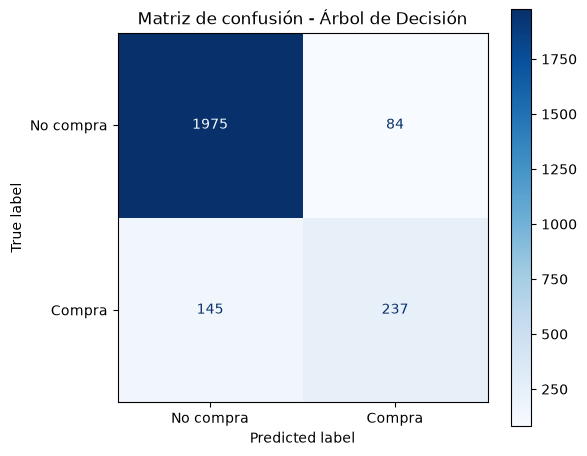

In [43]:
graficar_matriz_confusion("Árbol de Decisión", y_testclass, pred_dt)

<b>Interpretación de la Matriz de Confusión</b>

La matriz de confusión del Árbol de Decisión ilustra gráficamente un modelo con una alta capacidad para identificar la clase mayoritaria. En el cuadrante superior izquierdo, el intenso color azul oscuro destaca los 1975 verdaderos negativos (TN), confirmando que el algoritmo es sumamente eficaz al predecir cuando una sesión no culminará en una transacción. Esta precisión se complementa con el bajo número de falsos positivos (FP) ubicado en el cuadrante superior derecho (84 casos), lo que demuestra que el modelo rara vez emite falsas alarmas al etiquetar erróneamente a visitantes convencionales como compradores.

Por otro lado, la evaluación de la clase minoritaria (<code>Compra</code>) revela un comportamiento predictivo más conservador. El cuadrante inferior derecho contabiliza 237 verdaderos positivos (TP), representando las conversiones que el modelo logró identificar exitosamente. Sin embargo, el cuadrante inferior izquierdo registra 145 falsos negativos (FN), indicando que el algoritmo omitió a una porción considerable de compradores reales al clasificarlos en la categoría de <code>No compra</code>. A diferencia del algoritmo Bayesiano que priorizaba capturar todas las ventas a costa de equivocarse masivamente, este árbol establece fronteras de decisión mucho más estrictas; logra minimizar drásticamente las predicciones incorrectas, pero sacrifica sensibilidad, perdiendo el rastro de patrones de compra que resultan menos evidentes.

<b>Justificación del Árbol de Decisión</b>

El rendimiento apropiado del modelo de Árboles de Decisión, evidenciado en su alta precisión para clasificar correctamente los casos negativos, se justifica por la naturaleza matemática de este algoritmo. A diferencia del enfoque Bayesiano, los árboles no asumen independencia condicional entre las variables independientes ni exigen que los datos sigan una distribución normal. Esta flexibilidad estructural le permitió al algoritmo procesar sin colapsar la asimetría original de las métricas web y aprovechar directamente variables fuertemente predictivas para establecer umbrales lógicos secuenciales, aislando con éxito a la inmensa mayoría del tráfico que no genera ingresos sin disparar falsas alarmas masivas.

La pérdida de sensibilidad del árbol, que omitió 145 compradores reales, está asociada a las restricciones de regularización con las que se configuró el modelo: una profundidad máxima de 5 niveles y un tamaño mínimo de hoja equivalente al 0.5 % de los datos de entrenamiento (49 muestras). Estas restricciones obligan al algoritmo a generalizar y evitan que memorice el ruido, pero también pueden impedirle aislar recorridos de compra poco frecuentes. A esto se suma el desbalance de clases: como solo alrededor del 15 % de las sesiones termina en compra, un árbol que trata a ambas clases con el mismo peso tiende a priorizar la clase mayoritaria (<code>No compra</code>), porque equivocarse en ella reduce más el error global. Por ello, es probable que el recall bajo se deba tanto a la regularización como al desbalance.

Aumentar la profundidad máxima podría capturar a algunos de esos compradores omitidos, pero también aumenta el riesgo de sobreajuste, ya que el árbol crearía reglas muy específicas para aislar casos de la clase minoritaria y generalizaría peor ante datos nuevos. Existen otras alternativas para mejorar la sensibilidad, como ponderar las clases (class_weight="balanced") o ajustar el umbral de decisión, que normalmente elevan el recall a costa de la precisión.

<h3>1.7 Validación Estratificada Cruzada</h3>

Para asegurar una evaluación rigurosa y objetiva de los modelos, la secuencia lógica continúa con la configuración de una estrategia de validación cruzada estratificada (StratifiedKFold). Esta consideración técnica se implementó específicamente para mitigar el sesgo que podría generar una única partición de datos, dividiendo el conjunto de entrenamiento en 5 subconjuntos o iteraciones aleatorias pero reproducibles (n_splits=5, shuffle=True, random_state=42). Al utilizar una técnica estratificada en lugar de un corte simple, se garantiza estructuralmente que cada uno de estos cinco fragmentos mantenga de forma estricta la misma proporción de la clase minoritaria (<code>Compra</code>) presente en la fuente original, un paso matemático indispensable dado el fuerte desbalance de la variable objetivo.   

Posteriormente, se debe establecer de manera explícita el conjunto de métricas de evaluación que el sistema deberá calcular durante estas iteraciones, abarcando la exactitud (accuracy), precisión, sensibilidad (recall) y el F1-score. La decisión de configurar múltiples indicadores simultáneamente responde a la necesidad de medir el rendimiento de forma holística, ya que depender exclusivamente de la exactitud global resulta engañoso en escenarios desbalanceados. Finalmente, la lógica del bloque concluye inicializando un repositorio vacío (resultados_cv = {}), el cual actuará como un contenedor centralizado diseñado para capturar y consolidar sistemáticamente las puntuaciones de todos los algoritmos que pasen por la validación cruzada, facilitando su posterior comparación.  

In [44]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
resultados_cv = {}

<b>Funciones Auxiliares para Validación Cruzada</b>

<b>Nombre:</b> validar_modelo <br>
<b>Argumentos:</b> <br>
    <b>(String) nombre:</b> Representa el nombre del modelo que se va a utilizar en la comparación. <br>
    <b>(GaussianNB | DecisionTreeClassifier) modelo:</b> Representa el modelo que se va a evaluar. <br>
<b>Objetivo: </b> Mostrar una tabla de métricas que describen un modelo al realizar una validación cruzada. <br>
<b>Retorno:</b> -

In [45]:
def validar_modelo(nombre, modelo):
    cv = cross_validate(modelo, X_trainclass, y_trainclass, cv=skf, scoring=scoring)
    resultados_cv[nombre] = cv
    print(f"--- {nombre} ---")
    por_fold = pd.DataFrame({m: cv[f"test_{m}"] for m in scoring},
                            index=[f"Fold {i}" for i in range(1, 6)])
    por_fold.loc["Media"] = por_fold.mean()
    por_fold.loc["Desv. est."] = por_fold.iloc[:5].std()
    display(por_fold.round(4))

<b>Validación Cruzada con Naive Bayes</b>

In [46]:
validar_modelo("Naive Bayes", modelo_nb)

--- Naive Bayes ---


,accuracy,precision,recall,f1
Fold 1,0.2550,0.1726,0.9902,0.2940
Fold 2,0.2463,0.1709,0.9934,0.2916
Fold 3,0.2780,0.1752,0.9770,0.2971
Fold 4,0.2683,0.1740,0.9836,0.2957
Fold 5,0.2602,0.1733,0.9902,0.2949
Media,0.2616,0.1732,0.9869,0.2947
Desv. est.,0.0122,0.0016,0.0066,0.0020


<b>Interpretación de los Resultados de CV por Naive Bayes</b>

Los resultados de la validación cruzada para el modelo Naive Bayes confirman de manera concluyente que el desempeño deficiente observado en la evaluación inicial corresponde a una falla estructural del algoritmo frente a estos datos, y no a una anomalía de una partición específica. A lo largo de las cinco iteraciones (Fold 1 a Fold 5), la exactitud global (accuracy) promedia un 26.16% (0.2616), fluctuando apenas entre 0.2463 y 0.2780. Esta bajísima desviación estándar de 0.0122 demuestra que el modelo falla de manera sistemática y constante en la clasificación general de las sesiones, independientemente de cómo se organice la muestra de entrenamiento.

Al desglosar el comportamiento predictivo, las métricas confirman el sesgo extremo del algoritmo hacia la clase minoritaria. El modelo alcanza un recall medio sobresaliente del 98.69% (0.9869) pero por sí sola la métrica es engañosa, con una variabilidad casi inexistente (desviación estándar de 0.0066). Esto indica que el sistema logra identificar consistentemente casi todas las compras reales en todos los subconjuntos. Sin embargo, este comportamiento agresivo penaliza severamente la precisión, la cual se estanca en un promedio de 17.32% (0.1732). Esta enorme brecha confirma que la alta tasa de detección no es producto de un aprendizaje inteligente, sino de una condición del modelo que clasifica masivamente el tráfico como <code>Compra</code>, arrastrando una cantidad insostenible de falsos positivos en cada iteración.

Como consecuencia directa de este desequilibrio, la métrica de balance F1 promedia un 29.47% (0.2947). La extrema consistencia de estas puntuaciones confirma que la arquitectura del algoritmo GaussianNB es incompatible con la naturaleza de este conjunto de datos. El modelo no logra superar la asimetría de las variables continuas ni la expansión de dimensionalidad binaria del preprocesamiento, lo que anula su capacidad para establecer una decisión equilibrada y útil para un entorno de negocio.

<b>Validación Cruzada con Árbol de Decisión</b>

In [47]:
validar_modelo("Árbol de Decisión", modelo_dt)

--- Árbol de Decisión ---


,accuracy,precision,recall,f1
Fold 1,0.8914,0.6926,0.5523,0.6145
Fold 2,0.8879,0.6822,0.5279,0.5952
Fold 3,0.8961,0.6992,0.5869,0.6381
Fold 4,0.9037,0.6944,0.6852,0.6898
Fold 5,0.9001,0.7292,0.5738,0.6422
Media,0.8958,0.6995,0.5852,0.6360
Desv. est.,0.0064,0.0177,0.0602,0.0356


<b>Interpretación de los Resultados de CV por Árboles de Decisión</b>

Los resultados de la validación cruzada para el modelo de Árboles de Decisión confirman una notable consistencia en su rendimiento global y en su capacidad para evitar falsas alarmas. A lo largo de las cinco iteraciones, la exactitud media (accuracy) se mantiene estable en un 89.58% (0.8958), respaldada por una desviación estándar sumamente baja de 0.0064. De manera similar, la precisión de sus predicciones positivas es relativamente estable, promediando un 69.95% (0.6995) con una desviación estándar de 0.0177 y valores por fold entre 0.6822 y 0.7292. Estas cifras indican que el comportamiento conservador del árbol no fue una casualidad de la prueba inicial: sin importar cómo se dividan los datos, cuando el modelo clasifica a un usuario como comprador, mantiene una fiabilidad cercana al 70%.

Sin embargo, el análisis de esta validación expone una debilidad en la sensibilidad del algoritmo frente a la clase minoritaria. El recall promedia un 58.52% (0.5852) y es la métrica más inestable, con una desviación estándar de 0.0602. Al observar el comportamiento por subconjunto, la capacidad del modelo para detectar compradores fluctúa: en el Fold 4 logra capturar al 68.52% de las compras reales, mientras que en el Fold 2 baja al 52.79%. Esta variabilidad indica que las restricciones rígidas impuestas para evitar el sobreajuste (como la profundidad máxima) vuelven al modelo algo dependiente de los patrones específicos presentes en cada partición de entrenamiento.

Como consecuencia de esta inestabilidad en la captura de conversiones reales, el F1-score hereda dicha variabilidad, promediando un 63.60% (0.6360) y fluctuando entre 0.5952 y 0.6898 a lo largo de las iteraciones (desviación estándar de 0.0356). En conclusión, aunque el Árbol de Decisión es indiscutiblemente superior al enfoque Bayesiano al gestionar la asimetría y controlar los falsos positivos, la validación cruzada demuestra que sus fronteras de decisión son algo rígidas; cuando se enfrenta a un subconjunto donde los patrones de compra son menos evidentes, el modelo tiende a omitirlos, sacrificando sensibilidad de forma poco predecible.

<b>Resumen de Resultados</b>

In [48]:
resumen_cv = pd.DataFrame({
    nombre: {
        m: f"{cv['test_' + m].mean():.3f} ± {cv['test_' + m].std(ddof=1):.3f}"
        for m in scoring
    }
    for nombre, cv in resultados_cv.items()
})
resumen_cv

,Naive Bayes,Árbol de Decisión
accuracy,0.262 ± 0.012,0.896 ± 0.006
precision,0.173 ± 0.002,0.700 ± 0.018
recall,0.987 ± 0.007,0.585 ± 0.060
f1,0.295 ± 0.002,0.636 ± 0.036


<h3>1.8 Comparación de Modelos y Selección</h3>

In [49]:
sns.set_theme(style="whitegrid")

<b>Obtensión de Resultados Generales de los Modelos (Valores Exactos)</b>

In [50]:
base = DummyClassifier(strategy="most_frequent").fit(X_trainclass, y_trainclass)
m_base = metricas_manuales(y_testclass, base.predict(X_testclass))

claves = ["Accuracy", "Precision", "Recall", "F1"]
comparacion = pd.DataFrame({
    "Línea base (siempre No compra)": {k: m_base[k] for k in claves},
    "Naive Bayes": {k: m_nb[k] for k in claves},
    "Árbol de Decisión": {k: m_dt[k] for k in claves}
}).T
display(comparacion.round(4))

,Accuracy,Precision,Recall,F1
Línea base (siempre No compra),0.8435,0.0000,0.0000,0.0000
Naive Bayes,0.2692,0.1758,0.9948,0.2987
Árbol de Decisión,0.9062,0.7383,0.6204,0.6743


<b>Obtensión de Resultados Generales de los Modelos (Visualización Gráfica)</b>

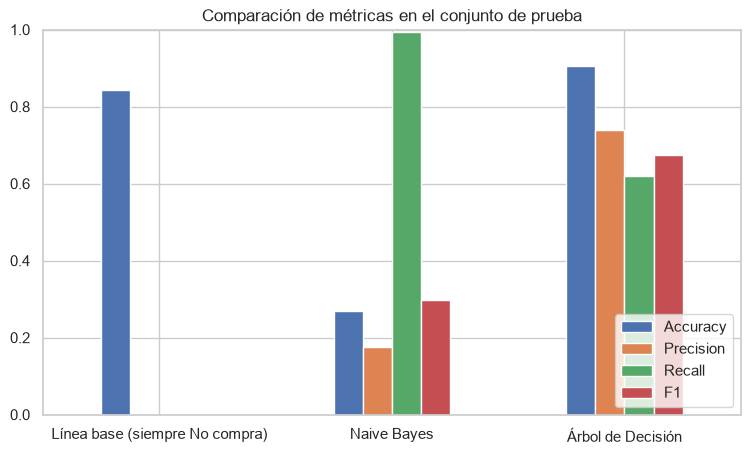

In [51]:
comparacion.plot(kind="bar", figsize=(9, 5), rot=0)
plt.title("Comparación de métricas en el conjunto de prueba")
plt.ylim(0, 1)
plt.legend(loc="lower right")
plt.show()

<b>Selección del Modelo más Apropiado</b>

El modelo de Árbol de Decisión es la opción más apropiada para su implementación técnica y comercial. Supera ampliamente a Naive Bayes en exactitud, precisión y F1-score. Al compararlo con una línea base que asume que ningún usuario comprará (84.35 % de exactitud), el árbol alcanza 90.62 % en la prueba y 89.58 % en validación cruzada. Naive Bayes, en cambio, llega a solo 26.92 % de exactitud, peor que la estrategia pasiva. En F1-score, el árbol obtiene 0.6743 frente a 0.2987. Naive Bayes sí logra un recall mayor (0.99 frente a 0.62), pero ese valor es engañoso: lo consigue clasificando casi todas las sesiones como Compra, lo que genera 1782 falsos positivos y una precisión de solo 0.18.

El árbol ofrece además alertas de conversión razonablemente confiables. La validación cruzada estima una precisión de 0.700 ± 0.018, es decir, que aproximadamente 7 de cada 10 usuarios identificados como compradores potenciales concretarían una transacción. Se trata de una estimación basada en datos históricos, que podría variar si cambia el comportamiento de los visitantes. A nivel estratégico, esto permite al equipo de marketing dirigir acciones de retargeting, como cupones o descuentos en tiempo real, a un público con mayor probabilidad real de compra, reduciendo el gasto en tráfico sin intención.

La limitación principal del modelo es su sensibilidad moderada y variable. El recall promedio en validación cruzada es de 0.585, con una desviación estándar de 0.060, por lo que el modelo omite alrededor del 41 % de los compradores reales. Comercialmente, esto representa un costo de oportunidad: una parte importante de los usuarios dispuestos a comprar navegará sin recibir estímulos, recomendaciones o incentivos de cierre, lo que puede traducirse en carritos abandonados y menores ventas.

La elección entre priorizar precisión o recall depende de la estructura de costos de las campañas. Si el negocio utiliza incentivos de alto costo, conviene mantener el árbol actual, que prioriza la precisión. Si las acciones son de bajo costo, como recordatorios por correo o banners emergentes, sería preferible capturar más compradores, y en ese caso podría explorarse una versión del modelo orientada al recall (por ejemplo, ponderando las clases o ajustando el umbral de decisión), aceptando una mayor proporción de falsos positivos. Esa alternativa no se evaluó en este trabajo y debería validarse antes de adoptarse.

<h3>Anexos Respecto al Árbol de Decisión</h3>

In [52]:
arbol = modelo_dt.named_steps["clf"]
nombres_feat = modelo_dt.named_steps["prep"].get_feature_names_out()
importancias = pd.Series(arbol.feature_importances_, index=nombres_feat).sort_values(ascending=False).head(10)

<b>Top de Carácteristicas de Importancia</b>

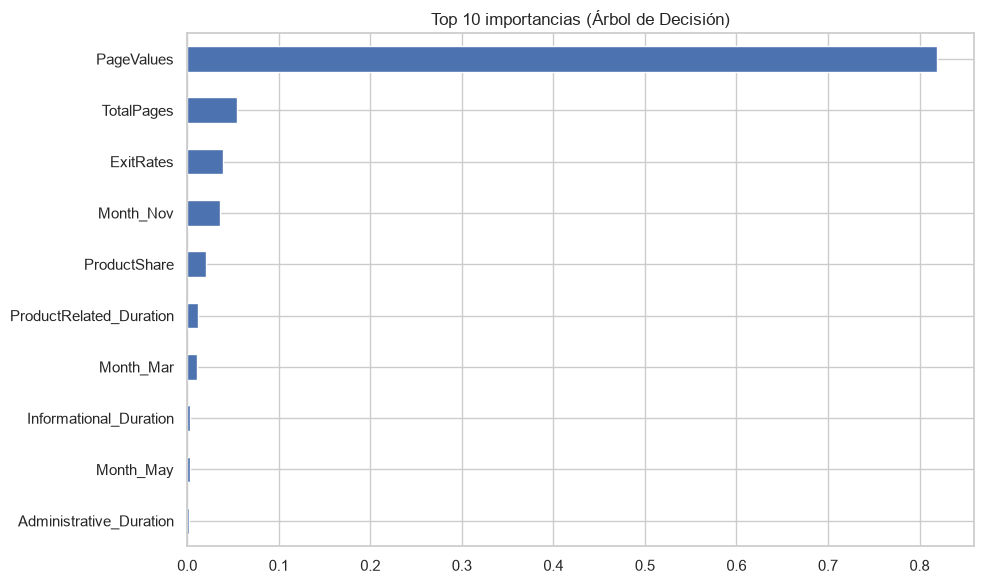

In [53]:
plt.figure(figsize=(10, 6))
importancias[::-1].plot(kind="barh", title="Top 10 importancias (Árbol de Decisión)")
plt.tight_layout()
plt.show()

<b>Primeros 3 Niveles del Árbol de Decisión</b>

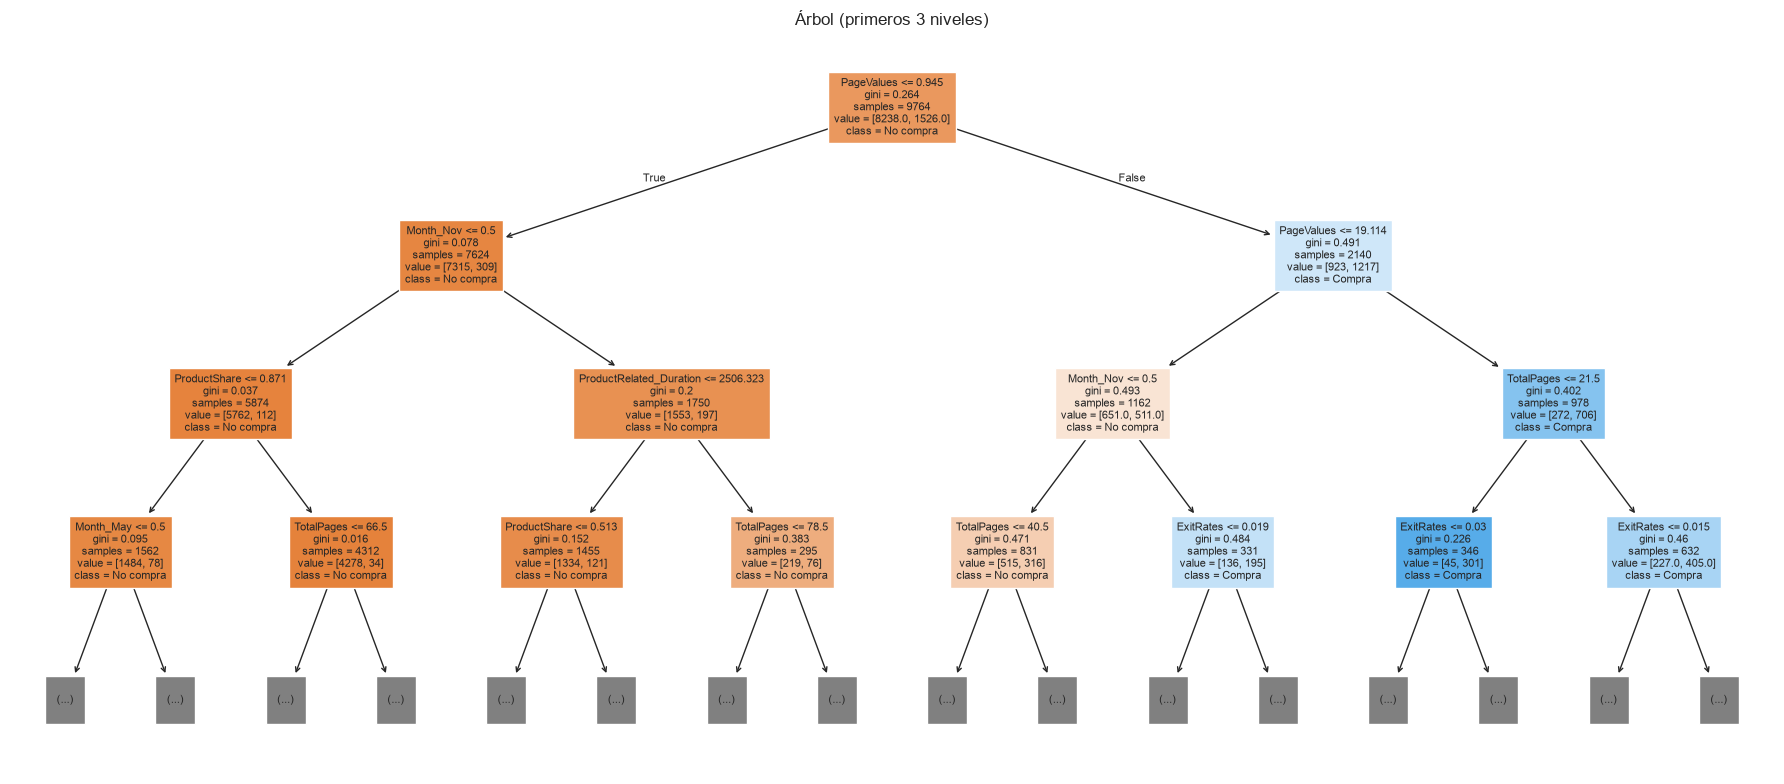

In [54]:
plt.figure(figsize=(18, 8))
plot_tree(arbol, max_depth=3, feature_names=nombres_feat, class_names=["No compra", "Compra"],
          filled=True, fontsize=8)
plt.title("Árbol (primeros 3 niveles)")
plt.tight_layout()
plt.show()

<h3>1.9 Pregunta de Análisis</h3>
<p><b>¿Qué consecuencias podrían tener los falsos positivos y los falsos negativos en el contexto del problema?</b>

Un falso positivo ocurre cuando el modelo clasifica como compradora una sesión que no terminará en compra. Su consecuencia principal es el gasto innecesario: si la empresa responde a esa predicción con un descuento, un cupón o una intervención de atención al cliente, estaría invirtiendo recursos en un visitante que no iba a comprar, o regalando un descuento a alguien que habría comprado de todos modos, lo que reduce el margen. Si las acciones son muy frecuentes, también pueden resultar molestas para los usuarios (ventanas emergentes, mensajes insistentes). En el árbol de decisión se registraron 84 falsos positivos en la prueba, mientras que Naive Bayes generó 1782, lo que haría inviable cualquier campaña basada en sus predicciones.

Un falso negativo ocurre cuando el modelo no detecta a un usuario que sí estaba dispuesto a comprar. Su consecuencia es una oportunidad perdida: el sistema no activa estímulos de cierre, como recordatorios, recomendaciones o asistencia en tiempo real, y la venta puede perderse por abandono del carrito. El árbol de decisión tuvo 145 falsos negativos, es decir, dejó sin atención a cerca del 38 % de los compradores reales de la prueba. Su costo es más difícil de medir que el de un falso positivo, porque corresponde a ingresos que no se obtuvieron y no a un gasto visible.

<b>¿Qué métrica considerarías más importante y por qué?</b>

Como métrica general para comparar los modelos, el F1-score es la más adecuada. Los datos están desbalanceados: solo alrededor del 15 % de las sesiones termina en compra y la línea base que predice siempre No compra alcanza 84.35 % de exactitud en la prueba. Por eso la exactitud es engañosa, ya que un modelo inútil obtiene un valor alto. El F1 combina precisión y recall, y penaliza tanto a un modelo que casi nunca acierta al predecir compra como a uno que deja pasar a la mayoría de los compradores. Esto se refleja en los resultados: el F1 distingue claramente al árbol (0.6743) de Naive Bayes (0.2987), mientras que Naive Bayes tiene un recall de 0.99 que, aislado, lo haría parecer bueno.

Sin embargo, la métrica más importante para tomar una decisión real depende del costo relativo de cada tipo de error. Si la acción sobre el cliente es costosa como descuentos altos o atención personalizada, conviene priorizar la precisión, para no desperdiciar recursos en falsos positivos. Por otro lado, si la acción es barata como un correo recordatorio, conviene priorizar el recall, porque perder un comprador cuesta más que contactar a alguien de más. En resumen, el F1-score es el criterio para seleccionar el modelo en ausencia de información sobre costos, y precisión o recall pasan a ser el criterio de operación cuando el negocio puede estimar el costo de cada error.
</p>

<h2>2. Modelos de Regresión</h2>
<hr>
<p>
A diferencia de la clasificación, que asigna cada observación a una categoría, los modelos de regresión estiman un valor numérico continuo. En el ámbito empresarial se usan para anticipar cantidades como las ventas, la demanda de un servicio o los ingresos del próximo mes, lo que ayuda a planificar los recursos con antelación.
    
En esta sección se desarrolla un problema de regresión con el conjunto de datos Seoul Bike Sharing Demand, que registra el alquiler de bicicletas por hora junto con las condiciones del clima y del calendario. El objetivo es estimar cuántas bicicletas se alquilarán en cada hora. Para ello se explora la fuente de datos y las relaciones entre sus variables, se describe el preprocesamiento aplicado y se construyen dos modelos, Regresión Lineal Múltiple y Árbol de Decisión para Regresión, que se comparan mediante MAE, RMSE y R². La sección cierra con un análisis de qué tan confiables son las predicciones para apoyar decisiones reales.
</p>

In [55]:
df_regresion = pd.read_csv("SeoulBikeData.csv", encoding="latin1")

<h3>2.1 Exploración de la Fuente de Datos</h3>
<p>Antes de iniciar el proceso de preparación es necesario conocer ciertos aspectos de la fuente de datos. En este caso se evaluaron los siguientes aspectos para saber el nivel de calidad de los datos existentes y si es necesario aplicar alguna transformación para realizar correcciones a alguno de los datos.</p>

<b>Inspección Inicial Básica</b>

In [56]:
print("Vista previa de los primeros 5 registros:")
df_regresion.head()

Vista previa de los primeros 5 registros:


,Date,Rented Bike Count,Hour,Temperature(°C),Humidity(%),Wind speed (m/s),Visibility (10m),Dew point temperature(°C),Solar Radiation (MJ/m2),Rainfall(mm),Snowfall (cm),Seasons,Holiday,Functioning Day
0,01/12/2017,254,0,-5.2,37,2.2,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
1,01/12/2017,204,1,-5.5,38,0.8,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
2,01/12/2017,173,2,-6.0,39,1.0,2000,-17.7,0.0,0.0,0.0,Winter,No Holiday,Yes
3,01/12/2017,107,3,-6.2,40,0.9,2000,-17.6,0.0,0.0,0.0,Winter,No Holiday,Yes
4,01/12/2017,78,4,-6.0,36,2.3,2000,-18.6,0.0,0.0,0.0,Winter,No Holiday,Yes


In [57]:
print("Forma de la fuente de datos: (Filas x Columnas)",df_regresion.shape)

Forma de la fuente de datos: (Filas x Columnas) (8760, 14)


<b>Aplicación de Correcciones Estéticas</b>

In [58]:
df_regresion.columns = ["Date","RentedBikeCount","Hour","Temperature","Humidity","WindSpeed",
                        "Visibility","DewPoint","SolarRadiation","Rainfall","Snowfall",
                        "Seasons","Holiday","FunctioningDay"]

df_regresion["Date"] = pd.to_datetime(df_regresion["Date"], format="%d/%m/%Y")

<b>Extracción de Nuevas Columnas para Enriquecer el Análisis</b>

<p>
Antes de construir los modelos de regresión es necesario preparar la estructura de los datos. A diferencia del problema de clasificación, en este conjunto la información está ordenada en el tiempo (un registro por cada hora), por lo que el orden de las observaciones es parte fundamental del problema y debe conservarse correctamente. En esta primera etapa se realizan las siguientes acciones:
</p>
<ol>
    <li> Los registros se ordenan por <code>Date</code> y <code>Hour</code> y se reinicia el índice con <code>reset_index</code>. Esto garantiza que cada fila esté en su posición temporal correcta, algo necesario para que más adelante la partición entre entrenamiento y prueba respete el orden cronológico (el 80 % más antiguo para entrenar y el 20 % más reciente para evaluar), sin mezclar horas del futuro en el entrenamiento.</li>
    <li>A partir de la fecha se extrae el día de la semana (0 = lunes, 6 = domingo) y también un indicador de si es fin de semana para que el modelo también contemple el impacto de estos días en la demanda de bicicletas. La fecha completa no puede ser utilizada directamente por los modelos como un valor numérico con sentido, pero el día de la semana sí aporta información útil: la demanda de bicicletas se comporta de forma distinta en días laborales y en fines de semana, por ejemplo, por los desplazamientos al trabajo. Esta es una de las transformaciones de ingeniería de características que se aplican en este problema.</li>
</ol>

In [59]:
df_regresion = df_regresion.sort_values(["Date","Hour"]).reset_index(drop=True)
df_regresion["DayOfWeek"] = df_regresion["Date"].dt.dayofweek
df_regresion["IsWeekend"] = df_regresion["DayOfWeek"].apply(lambda x: "Yes" if x >= 5 else "No")

<b>Consideraciones de Análisis de Calidad de los Datos</b>
<ul>
    <li>Validar la existencia de los valores nulos.</li>
    <li>Validar que los tipos de datos sean consistentes con la información que almacenan.</li>
    <li>Validar que las variables categóricas que almacenan texto no tengan conflictos tipográficos.</li>
</ul>

In [60]:
print("Cantidad de valores vacios en cada columna:")
df_regresion.isna().sum()

Cantidad de valores vacios en cada columna:


Date               0
RentedBikeCount    0
Hour               0
Temperature        0
Humidity           0
WindSpeed          0
Visibility         0
DewPoint           0
SolarRadiation     0
Rainfall           0
Snowfall           0
Seasons            0
Holiday            0
FunctioningDay     0
DayOfWeek          0
IsWeekend          0
dtype: int64

In [61]:
print("Información de los tipos de datos y valores no nulos:")
df_regresion.info()

Información de los tipos de datos y valores no nulos:
<class 'pandas.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Date             8760 non-null   datetime64[us]
 1   RentedBikeCount  8760 non-null   int64         
 2   Hour             8760 non-null   int64         
 3   Temperature      8760 non-null   float64       
 4   Humidity         8760 non-null   int64         
 5   WindSpeed        8760 non-null   float64       
 6   Visibility       8760 non-null   int64         
 7   DewPoint         8760 non-null   float64       
 8   SolarRadiation   8760 non-null   float64       
 9   Rainfall         8760 non-null   float64       
 10  Snowfall         8760 non-null   float64       
 11  Seasons          8760 non-null   str           
 12  Holiday          8760 non-null   str           
 13  FunctioningDay   8760 non-null   str           
 1

In [62]:
print("Validación de los valores de las variables categóricas:")
print("Valores de Seasons: ",df_regresion["Seasons"].unique())
print("Valores de Holiday: ",df_regresion["Holiday"].unique())
print("Valores de FunctioningDay: ",df_regresion["FunctioningDay"].unique())

Validación de los valores de las variables categóricas:
Valores de Seasons:  <ArrowStringArray>
['Winter', 'Spring', 'Summer', 'Autumn']
Length: 4, dtype: str
Valores de Holiday:  <ArrowStringArray>
['No Holiday', 'Holiday']
Length: 2, dtype: str
Valores de FunctioningDay:  <ArrowStringArray>
['Yes', 'No']
Length: 2, dtype: str


<b>Consideraciones de la Exploración Estadística</b>
<ul>
    <li>Visualizar la media, valor mínimo, valor máximo y el rango de valores que tienen algunas columnas numéricas importantes.</li>
    <li>Utilizar visualizaciones para conocer algunos patrones que pueden ser de interes.</li>
    <li>Validar la distribución de los datos de la variable objetivo para conocer como los datos se distribuiran antes de realizar la estratificación en el modelo.</li>
</ul>

In [63]:
descripcion_estadistica_numerica(df_regresion,"RentedBikeCount")

Media de RentedBikeCount : 704.6020547945205
Valor Mínimo de RentedBikeCount : 0
Valor Máximo de RentedBikeCount : 3556
Rango de Valores en RentedBikeCount (maximo - minimo): 3556
Desviación Estándar en RentedBikeCount 644.9974677392156


In [64]:
descripcion_estadistica_numerica(df_regresion,"Temperature")

Media de Temperature : 12.882922374429223
Valor Mínimo de Temperature : -17.8
Valor Máximo de Temperature : 39.4
Rango de Valores en Temperature (maximo - minimo): 57.2
Desviación Estándar en Temperature 11.944825230027947


In [65]:
descripcion_estadistica_numerica(df_regresion,"Visibility")

Media de Visibility : 1436.825799086758
Valor Mínimo de Visibility : 27
Valor Máximo de Visibility : 2000
Rango de Valores en Visibility (maximo - minimo): 1973
Desviación Estándar en Visibility 608.2987119840188


In [66]:
descripcion_estadistica_numerica(df_regresion,"Rainfall")

Media de Rainfall : 0.14868721461187215
Valor Mínimo de Rainfall : 0.0
Valor Máximo de Rainfall : 35.0
Rango de Valores en Rainfall (maximo - minimo): 35.0
Desviación Estándar en Rainfall 1.1281929687321486


In [67]:
descripcion_estadistica_numerica(df_regresion,"Snowfall")

Media de Snowfall : 0.07506849315068492
Valor Mínimo de Snowfall : 0.0
Valor Máximo de Snowfall : 8.8
Rango de Valores en Snowfall (maximo - minimo): 8.8
Desviación Estándar en Snowfall 0.4367461811249922


In [68]:
print("Distribución de RentedBikeCount según los Valores de FunctioningDay:")
print(df_regresion.groupby("FunctioningDay")["RentedBikeCount"].sum())

Distribución de RentedBikeCount según los Valores de FunctioningDay:
FunctioningDay
No           0
Yes    6172314
Name: RentedBikeCount, dtype: int64


In [69]:
print("Distribución de RentedBikeCount según los Valores de Holiday:")
df_regresion.groupby("Holiday")["RentedBikeCount"].sum()

Distribución de RentedBikeCount según los Valores de Holiday:


Holiday
Holiday        215895
No Holiday    5956419
Name: RentedBikeCount, dtype: int64

Text(0.5, 1.0, 'Cantidad de Bicicletas Rentadas vs Cantidad de Nieve en cm Caida')

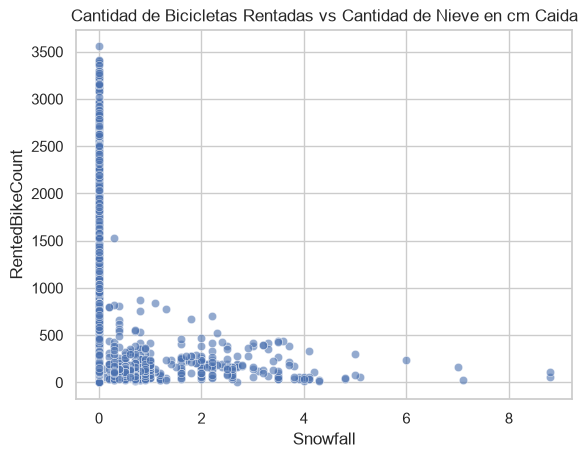

In [70]:
(sns.scatterplot(data=df_regresion, x="Snowfall", y="RentedBikeCount", alpha=0.6)).set_title("Cantidad de Bicicletas Rentadas vs Cantidad de Nieve en cm Caida")

Text(0.5, 1.0, 'Cantidad de Bicicletas Rentadas vs Cantidad de Lluvia en mm Caida')

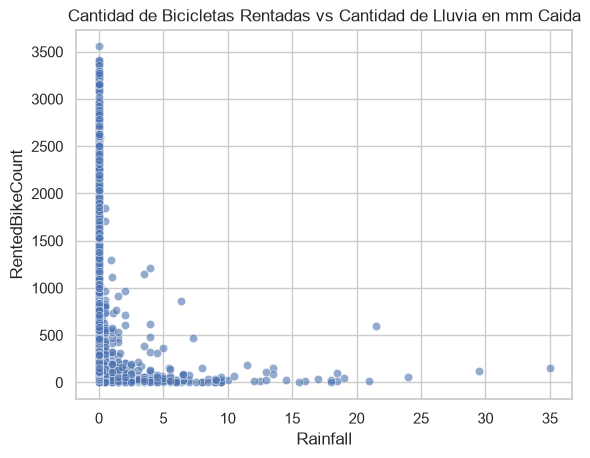

In [71]:
(sns.scatterplot(data=df_regresion, x="Rainfall", y="RentedBikeCount", alpha=0.6)).set_title("Cantidad de Bicicletas Rentadas vs Cantidad de Lluvia en mm Caida")

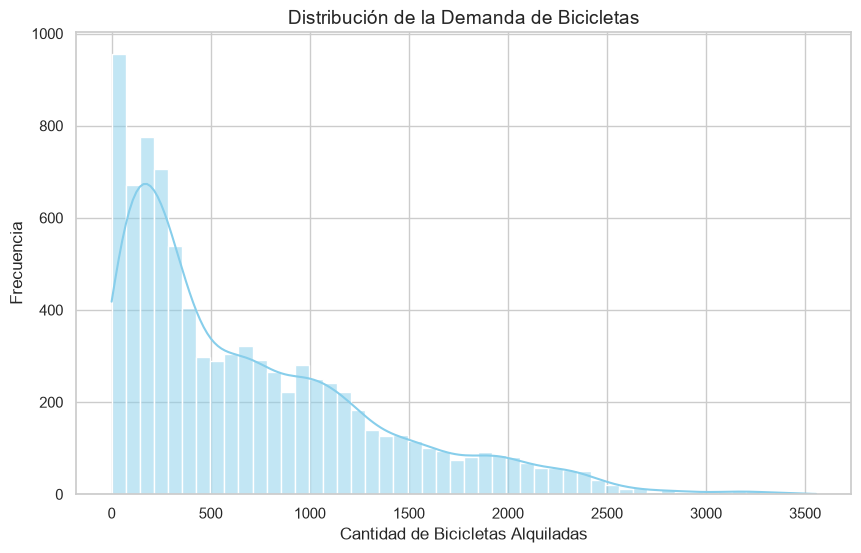

In [72]:
plt.figure(figsize=(10, 6))
sns.histplot(data=df_regresion, x="RentedBikeCount", kde=True, bins=50, color="skyblue")
plt.title("Distribución de la Demanda de Bicicletas", fontsize=14)
plt.xlabel("Cantidad de Bicicletas Alquiladas")
plt.ylabel("Frecuencia")
plt.show()

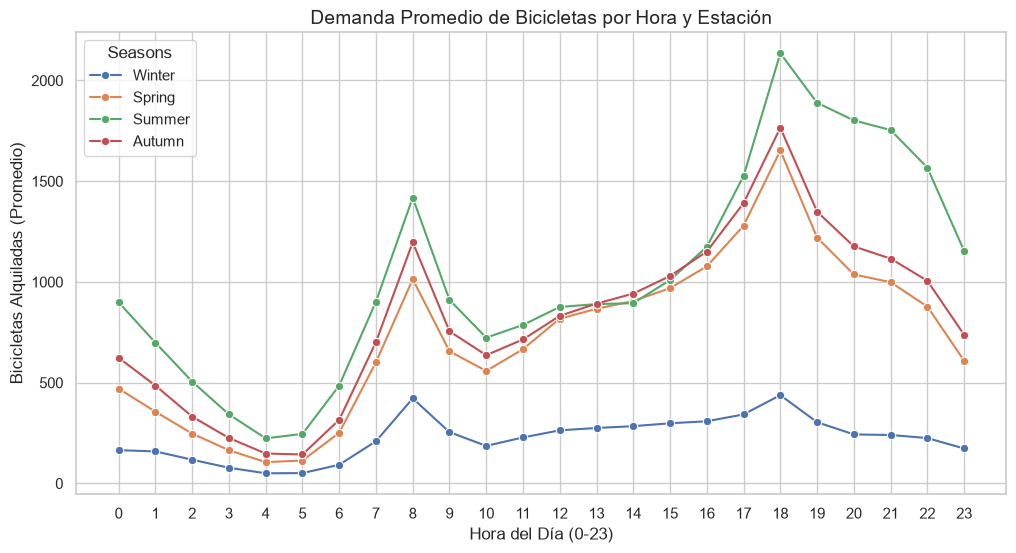

In [73]:
plt.figure(figsize=(12, 6))
sns.lineplot(data=df_regresion, x="Hour", y="RentedBikeCount", hue="Seasons", errorbar=None, marker="o")
plt.title("Demanda Promedio de Bicicletas por Hora y Estación", fontsize=14)
plt.xlabel("Hora del Día (0-23)")
plt.ylabel("Bicicletas Alquiladas (Promedio)")
plt.xticks(range(0, 24))
plt.show()

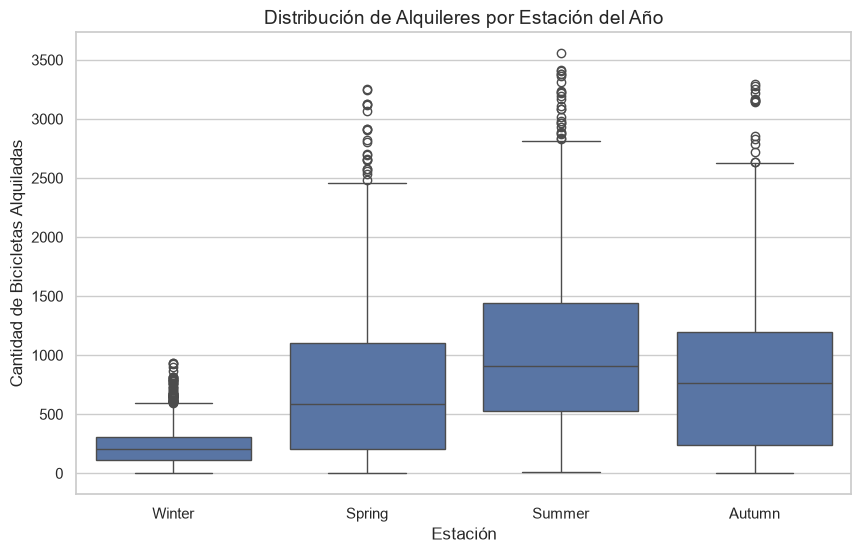

In [74]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_regresion, x="Seasons", y="RentedBikeCount")
plt.title("Distribución de Alquileres por Estación del Año", fontsize=14)
plt.xlabel("Estación")
plt.ylabel("Cantidad de Bicicletas Alquiladas")
plt.show()

<b>Conclusiones de la Exploración de la Fuente de Datos</b>

El conjunto de datos contiene 8,760 registros, correspondientes a observaciones horarias durante un año completo, y está estructurado en 14 variables. La inspección inicial confirma que el dataset tiene un alto nivel de calidad, ya que no presenta valores nulos en ninguna de sus columnas. Los tipos de datos se dividen lógicamente: la variable objetivo y las métricas horarias son enteras, los factores meteorológicos (temperatura, precipitación, radiación) son de punto flotante, y las variables de calendario como fecha, estación y festividades están almacenadas como texto. 

Desde la perspectiva temporal y categórica, el conjunto de datos abarca las cuatro estaciones del año (Primavera, Verano, Otoño, Invierno), distribuidas uniformemente a lo largo del año calendario. La mayoría de los registros corresponden a días no festivos y operativos, lo que indica que el modelo tendrá un sólido conjunto de datos de entrenamiento para la operación habitual del sistema, aunque deberá prestarse atención a cómo las excepciones (días festivos o no operativos) impactan la demanda.

En el análisis de las variables meteorológicas, se observa que la variable objetivo, el recuento de bicicletas alquiladas (Rented Bike Count), presenta fluctuaciones significativas vinculadas a los ciclos diarios (representados por la variable Hour). Las condiciones climáticas, como la temperatura (Temperature), la humedad (Humidity) y el punto de rocío (DewPoint), son factores críticos. Es previsible que exista una fuerte correlación positiva entre la temperatura y el punto de rocío, lo que podría introducir multicolinealidad en modelos de regresión lineal. Variables adicionales como la radiación solar, la velocidad del viento, la precipitación y las nevadas proporcionan un contexto ambiental completo, donde valores extremos (lluvia intensa o nieve) probablemente se asocien con una disminución drástica en la demanda. 

En conjunto, los datos están limpios y son robustos para el modelado. La predicción de la demanda de bicicletas no depende de un solo factor, sino de la compleja interacción entre la hora del día, la estación del año y las condiciones climáticas exactas. Esto justifica la necesidad de construir y comparar modelos predictivos avanzados, como la Regresión Lineal Múltiple para entender las relaciones base, y los Árboles de Decisión para Regresión (o modelos de ensamble) capaces de capturar relaciones no lineales complejas y los efectos combinados de las variables climáticas sobre la demanda. Para obtener modelos precisos, será crucial el preprocesamiento previo: aplicar codificación dummy (OneHotEncoder) a las variables estacionales y de calendario, y escalar estandarizadamente las diversas métricas climáticas.

<h3>2.2 Identificación de Variables</h3>

El conjunto de datos para este modelo de regresión contiene 8,760 registros y 14 columnas. Cada registro corresponde a una hora del sistema de bicicletas compartidas de Seúl, y como 8,760 equivale a 365 días por 24 horas, los datos cubren un año completo de mediciones. De las 14 columnas, la fuente de datos asigna el rol de característica a 13 y el de objetivo a una: “RentedBikeCount”. Esta variable, de tipo entero, indica el número de bicicletas alquiladas en cada hora y su predicción es la parte clave del problema, ya que permite estimar la demanda para mantener un suministro estable de bicicletas y reducir el tiempo de espera del público.

Un primer grupo de variables describe el momento en que ocurre cada registro. “Date” (fecha) indica el día del año y “Hour” (entero) señala la hora del día. A ellas se suman “Seasons” (texto), que indica la estación del año (invierno, primavera, verano u otoño), y “Holiday” (texto), que señala si ese día es feriado o no. Por último, “Functioning Day” (texto) actúa como una característica adicional que indica si la hora corresponde a un periodo en que el sistema de alquiler estaba operativo.

El resto de las variables, todas con rol de característica, describe las condiciones del clima en cada hora. “Temperature” (decimal) es la temperatura en grados Celsius y “DewPoint” (decimal) es el punto de rocío, también en grados Celsius. “Humidity” (entero) mide la humedad en porcentaje y “WindSpeed” (decimal) la velocidad del viento en metros por segundo. “Visibility” (entero) indica qué tan lejos se puede ver, en unidades de 10 metros, y “SolarRadiation” (decimal) mide la radiación solar en MJ/m². Finalmente, “Rainfall” (decimal) registra la precipitación en milímetros y “Snowfall” (decimal) la nieve en centímetros.

En cuanto a sus relaciones con la demanda, lo esperable es que se alquilen más bicicletas cuando el clima es agradable y menos cuando llueve o nieva, y que la hora del día influya, con aumentos en los horarios de entrada y salida del trabajo. También hay variables que se parecen entre sí, como “Temperature” y “DewPoint”, porque ambas dependen de las condiciones del aire. Estas relaciones se comprueban con los gráficos de dispersión y las correlaciones de la exploración.

<table style="border-collapse: collapse; width: 100%;">
  <caption style="text-align: left; font-weight: bold; padding: 6px 0;">Tabla de Variables</caption>
  <thead>
    <tr>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Nombre</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Rol</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Tipo</th>
      <th style="border: 1px solid gray; padding: 6px; text-align: left;">Valores Faltantes</th>
    </tr>
  </thead>
  <tbody>
    <tr><td style="border: 1px solid gray; padding: 6px;">Date</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Fecha</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">RentedBikeCount</td><td style="border: 1px solid gray; padding: 6px;">Objetivo</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Hour</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Temperature</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Humidity</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">WindSpeed</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Visibility</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Entero</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">DewPoint</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">SolarRadiation</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Rainfall</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Snowfall</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Decimal</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Seasons</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Texto</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">Holiday</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Booleano</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
    <tr><td style="border: 1px solid gray; padding: 6px;">FunctioningDay</td><td style="border: 1px solid gray; padding: 6px;">Característica</td><td style="border: 1px solid gray; padding: 6px;">Booleano</td><td style="border: 1px solid gray; padding: 6px;">No</td></tr>
  </tbody>
</table>
<i>Tabla de variables identificadas en Seoul Bike Sharing Demand (UCI).</i>

<h3> 2.3 Identificación de las Relaciones entre las Variables</h3>

Para conocer el nivel de relación que tienen las variables, se desarrollo un conjunto de gráficos para conocer como interactuan algunas variables entre sí. En este caso se evaluaron los siguientes aspectos para saber las relaciones que poseen las variables entre ellas.

<ul>
    <li>Identificar la correlación que existe entre las variables numéricas.<br></li>
    <li>Identificar la relación entre las variables climáticas y la demanda de bicicletas.<br></li>
    <li>Identificar la la relación entre la estación del año y la demanda de bicicletas.<br></li>
</ul>

Text(0.5, 1.0, 'Correlación entre métricas de renta de bicicletas')

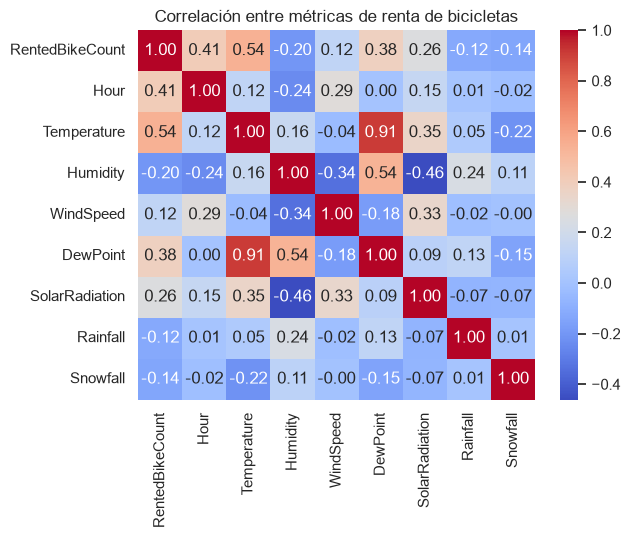

In [75]:
cols_num = ["RentedBikeCount", "Hour","Temperature","Humidity","WindSpeed","DewPoint","SolarRadiation",
            "Rainfall","Snowfall"]
sns.heatmap(df_regresion[cols_num].corr(), annot=True, cmap="coolwarm", fmt=".2f").set_title("Correlación entre métricas de renta de bicicletas")

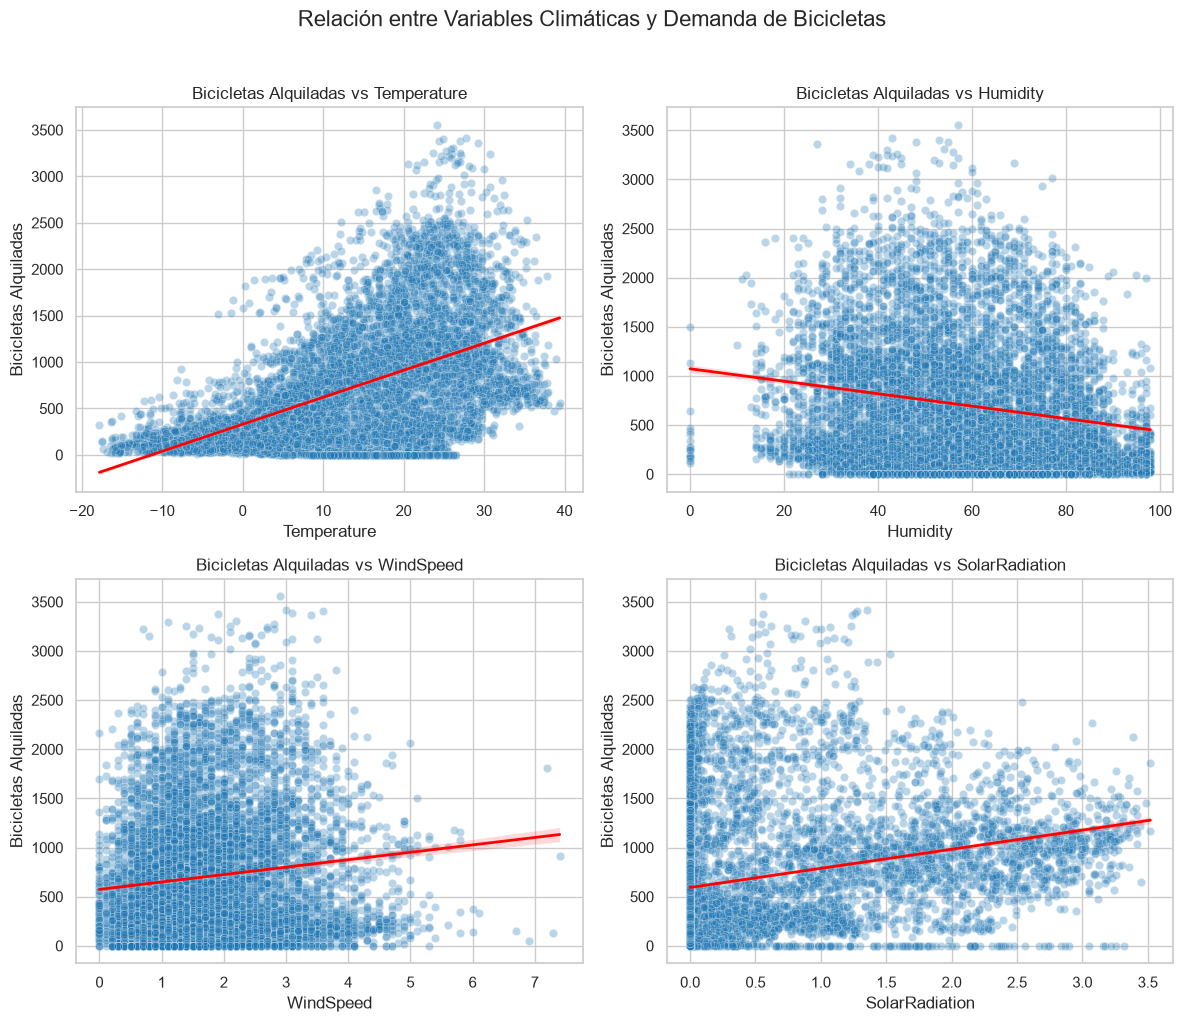

In [76]:
variables_independientes = ["Temperature", "Humidity", "WindSpeed", "SolarRadiation"]

fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 10))
fig.suptitle("Relación entre Variables Climáticas y Demanda de Bicicletas", fontsize=16, y=1.02)

axes = axes.flatten()

for i, var in enumerate(variables_independientes):
    sns.scatterplot(data=df_regresion, x=var, y="RentedBikeCount", 
                    alpha=0.3, ax=axes[i], color="#1f77b4")
    
    sns.regplot(data=df_regresion, x=var, y="RentedBikeCount", 
                scatter=False, ax=axes[i], color="red", line_kws={"linewidth": 2})
    
    axes[i].set_title(f"Bicicletas Alquiladas vs {var}", fontsize=12)
    axes[i].set_ylabel("Bicicletas Alquiladas")

plt.tight_layout()
plt.show()

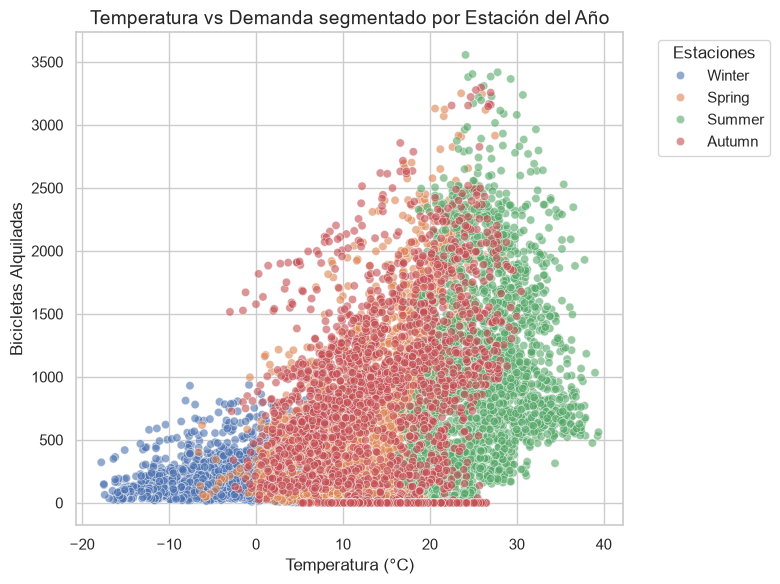

In [77]:
plt.figure(figsize=(8, 6))

sns.scatterplot(data=df_regresion, x="Temperature", y="RentedBikeCount", 
                hue="Seasons", alpha=0.6)

plt.title("Temperatura vs Demanda segmentado por Estación del Año", fontsize=14)
plt.xlabel("Temperatura (°C)")
plt.ylabel("Bicicletas Alquiladas")
plt.legend(title="Estaciones", bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()

<b>Conclusiones de la Identificación de Relaciones entre las Variables</b>

<h3>2.4 Variable Objetivo del Problema</h3>


<h3>2.5 Preparación y Preprocesamiento de los Modelos</h3>

Luego de establecer las propiedades básicas faltantes del modelo, se define <code>y_regresion</code> con la columna RentedBikeCount, que es el valor que se desea predecir (número de bicicletas alquiladas por hora). Posteriormente, Se construye <code>X_regresion</code> con el resto de las columnas, excluyendo las siguientes:

<ul>
    <li>RentedBikeCount, porque es la variable objetivo y no puede formar parte de los datos con los que se predice.<br></li>
    <li>Date, porque ya fue utilizada para ordenar los datos y derivar <code>DayOfWeek</code>. Mantenerla no aportaría información adicional y sus valores únicos no se repiten entre entrenamiento y prueba, por lo que el modelo no podría generalizar a partir de ella.<br></li>
    <li>DewPoint (punto de rocío), porque en el análisis exploratorio mostró una correlación muy alta con Temperature. Al aportar información prácticamente redundante, se elimina para reducir la multicolinealidad, que afecta sobre todo a la Regresión Lineal al dificultar la interpretación de sus coeficientes.</li>
</ul>

In [78]:
y_regresion = df_regresion["RentedBikeCount"]
X_regresion = df_regresion.drop(columns=["RentedBikeCount","Date","DewPoint"])

<b>Dummificación y Escalado Estándar de las Variables</b>

SI

In [79]:
cat_regresion = ["Hour","Seasons","Holiday","FunctioningDay","DayOfWeek","IsWeekend"]
num_reg_final = [c for c in X_regresion.columns if c not in cat_regresion]

def crear_preprocesador_reg(metodo):
    escalador = StandardScaler() if metodo == "lr" else "passthrough"
    prep = ColumnTransformer([
        ("num", escalador, num_reg_final),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_regresion)
    ], verbose_feature_names_out=False)
    prep.set_output(transform="pandas")
    return prep

<b>División de los Bloques de Entrenamiento y Prueba</b>

SI

In [80]:
corte = int(len(X_regresion) * 0.8)
X_trainreg, X_testreg = X_regresion.iloc[:corte], X_regresion.iloc[corte:]
y_trainreg, y_testreg = y_regresion.iloc[:corte], y_regresion.iloc[corte:]

In [81]:
print("Entrenamiento:", df_regresion["Date"].iloc[0].date(), "→", df_regresion["Date"].iloc[corte-1].date())
print("Prueba: ", df_regresion["Date"].iloc[corte].date(), "→", df_regresion["Date"].iloc[-1].date())
print("Seasons en el Coonjunto de Entrenamiento: \n",X_trainreg["Seasons"].value_counts(),"\nSeasons en el Conjunto de Prueba: \n", X_testreg["Seasons"].value_counts())

Entrenamiento: 2017-12-01 → 2018-09-18
Prueba:  2018-09-19 → 2018-11-30
Seasons en el Coonjunto de Entrenamiento: 
 Seasons
Spring    2208
Summer    2208
Winter    2160
Autumn     432
Name: count, dtype: int64 
Seasons en el Conjunto de Prueba: 
 Seasons
Autumn    1752
Name: count, dtype: int64


<h3>2.6 Construcción de los Modelos</h3>
<p>
</p>

<b>Entrenamiento del Modelo de Regresión por Regresión Lineal Múltiple</b>

In [82]:
modelo_lr = Pipeline([("prep", crear_preprocesador_reg("lr")), ("reg", LinearRegression())])
modelo_lr.fit(X_trainreg, y_trainreg)
pred_lr  = modelo_lr.predict(X_testreg)

<b>Visualización del Conjunto de Entrenamiento</b>

In [83]:
X_train_transf = modelo_lr.named_steps["prep"].transform(X_trainreg)
display(X_train_transf.head())
print(X_train_transf.shape)

,Temperature,Humidity,WindSpeed,Visibility,SolarRadiation,Rainfall,Snowfall,Hour_0,Hour_1,Hour_2,...,FunctioningDay_Yes,DayOfWeek_0,DayOfWeek_1,DayOfWeek_2,DayOfWeek_3,DayOfWeek_4,DayOfWeek_5,DayOfWeek_6,IsWeekend_No,IsWeekend_Yes
0,-1.408695,-1.024197,0.390631,0.944999,-0.660408,-0.131211,-0.188765,1.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-1.431758,-0.975794,-0.938594,0.944999,-0.660408,-0.131211,-0.188765,0.0,1.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
2,-1.470197,-0.927390,-0.748705,0.944999,-0.660408,-0.131211,-0.188765,0.0,0.0,1.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
3,-1.485573,-0.878986,-0.843650,0.944999,-0.660408,-0.131211,-0.188765,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
4,-1.470197,-1.072601,0.485575,0.944999,-0.660408,-0.131211,-0.188765,0.0,0.0,0.0,...,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


(7008, 48)


In [84]:
X_train_transf.info()

<class 'pandas.DataFrame'>
RangeIndex: 7008 entries, 0 to 7007
Data columns (total 48 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Temperature         7008 non-null   float64
 1   Humidity            7008 non-null   float64
 2   WindSpeed           7008 non-null   float64
 3   Visibility          7008 non-null   float64
 4   SolarRadiation      7008 non-null   float64
 5   Rainfall            7008 non-null   float64
 6   Snowfall            7008 non-null   float64
 7   Hour_0              7008 non-null   float64
 8   Hour_1              7008 non-null   float64
 9   Hour_2              7008 non-null   float64
 10  Hour_3              7008 non-null   float64
 11  Hour_4              7008 non-null   float64
 12  Hour_5              7008 non-null   float64
 13  Hour_6              7008 non-null   float64
 14  Hour_7              7008 non-null   float64
 15  Hour_8              7008 non-null   float64
 16  Hour_9           

<b>Entrenamiento del Modelo de Regresión por Árboles de Decisión para Regresión</b>
<p>
SI
</p>

In [85]:
modelo_dtr = Pipeline([("prep", crear_preprocesador_reg("dt")),
                       ("reg", DecisionTreeRegressor(max_depth=10,
                               min_samples_leaf=calcular_min_samples_leaf(len(X_trainreg),0.001),
                               random_state=42))])
modelo_dtr.fit(X_trainreg, y_trainreg)
pred_dtr = modelo_dtr.predict(X_testreg)

<b>Funciones Auxiliares para Evaluar los Modelos de Regresión</b>

<b>Nombre:</b> evaluar_regresion <br>
<b>Argumentos:</b> <br>
    <b>(String) nombre:</b> Representa el nombre del modelo que se va a evaluar, y se utiliza para identificar la fila correspondiente en la tabla de resultados. <br>
    <b>(Series) y_real:</b> Representa los valores reales de la variable objetivo en el conjunto de prueba. <br>
    <b>(Array) y_pred:</b> Representa los valores obtenidos mediante las predicciones del modelo para ese mismo conjunto de prueba. <br>
<b>Objetivo: </b> Calcular las métricas de error de un modelo de regresión: el MAE, el RMSE y el R². <br>
<b>Retorno:</b> (Dictionary) Retorna un conjunto de valores ordenados de forma clave-valor con el nombre del modelo y el resultado de cada una de las métricas.

In [86]:
def evaluar_regresion(nombre, y_real, y_pred):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    r2 = r2_score(y_real, y_pred)
    return {"Modelo": nombre, "MAE": mae, "RMSE": rmse, "R²": r2,
            "MAE / media real": mae / y_real.mean()}

<h3>2.7 Evaluación de los Modelos de Regresión</h3>
<p>
A continuación se construye la tabla comparativa con las métricas de los tres modelos sobre el conjunto de prueba. Primero se crea un <b>modelo de referencia</b> con <code>DummyRegressor(strategy="mean")</code>, que se entrena con <code>y_trainreg</code> y siempre predice el promedio de la demanda del entrenamiento, sin importar las características que se le pida estimar. No es un modelo que se pretenda utilizar, sino un punto de comparación mínimo, es decir, cualquier modelo útil debe obtener mejores resultados que simplemente predecir el promedio, y de lo contrario no estaría aprendiendo ningún patrón de los datos.

Luego se llamará a la función <code>evaluar_regresion</code> una vez por cada modelo: el modelo de referencia, la Regresión Lineal (<code>pred_lr</code>) y el Árbol de Regresión (<code>pred_dtr</code>), comparando siempre sus predicciones con los mismos valores reales (<code>y_testreg</code>). Cada llamada devuelve un diccionario con las métricas, y los tres diccionarios se reunirán en un DataFrame de pandas, usando <code>set_index("Modelo")</code> para que el nombre del modelo sea el identificador de cada fila. Finalmente, se mostrará la tabla con los valores redondeados a cuatro decimales, donde cada fila representa un modelo y cada columna una métrica (MAE, RMSE, R² y MAE / media real), lo que permitirá compararlos de forma directa.
</p>

In [87]:
base = DummyRegressor(strategy="mean").fit(X_trainreg, y_trainreg)
resultados_reg = pd.DataFrame([
    evaluar_regresion("Base (media)", y_testreg, base.predict(X_testreg)),
    evaluar_regresion("Regresión Lineal Múltiple", y_testreg, pred_lr),
    evaluar_regresion("Árbol de Regresión", y_testreg, pred_dtr)]).set_index("Modelo")
display(resultados_reg.round(4))

,MAE,RMSE,R²,MAE / media real
Modelo,,,,
Base (media),500.9994,616.8193,-0.0114,0.6618
Regresión Lineal Múltiple,256.7584,343.2263,0.6868,0.3392
Árbol de Regresión,388.6962,548.2053,0.2011,0.5135


<b>Interpretación de las Métricas</b>
<p>

</p>

<b>Justificación de las Métricas</b>


<b>Representación Gráfica de los Resultados Reales vs Predichos</b>

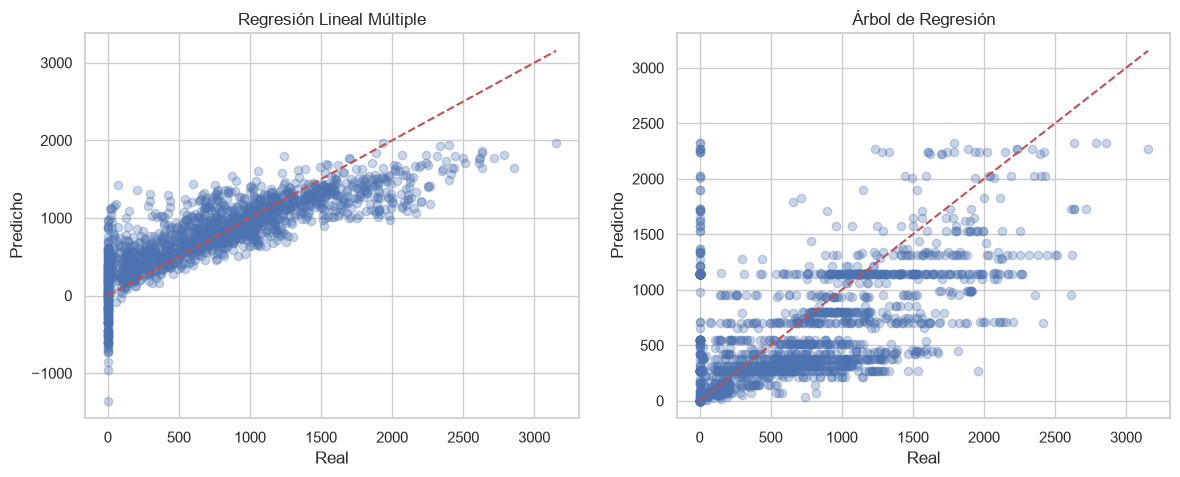

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (n, p) in zip(axes, [("Regresión Lineal Múltiple", pred_lr), ("Árbol de Regresión", pred_dtr)]):
    ax.scatter(y_testreg, p, alpha=0.3)
    ax.plot([0, y_testreg.max()], [0, y_testreg.max()], "r--")
    ax.set(title=n, xlabel="Real", ylabel="Predicho")
plt.show()

<b>Gráfica Alternativa de las Últimas 2 Semanas para Comprender las Diferencias</b>

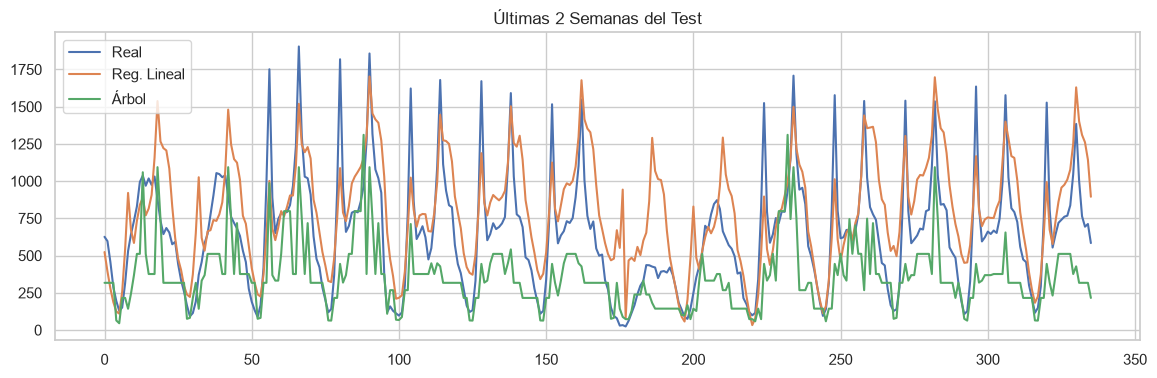

In [89]:
ult = 24 * 14
plt.figure(figsize=(14, 4))
plt.plot(y_testreg.values[-ult:], label="Real")
plt.plot(pred_lr[-ult:], label="Reg. Lineal")
plt.plot(pred_dtr[-ult:], label="Árbol")
plt.legend(); plt.title("Últimas 2 Semanas del Test")
plt.show()

<b>Interpretación de las Visualizaciones de Valores Reales y Predichos</b>
<p>
</p>

<h3>2.8 Comparación de los Modelos y Selección</h3>



<h3>2.9 Preguntas de Análisis</h3>

<b>¿Consideras que el modelo seleccionado proporciona predicciones suficientemente confiables para apoyar decisiones reales en la organización? Justifica tu respuesta utilizando las métricas obtenidas.</b>



<h2>3. Conclusiones respecto a la Interpretación desde la Inteligencia de Negocios</h2>